In [ ]:
# Общие импорты и локальные данные JERICHON
import os, sys
from pathlib import Path

_HERE = Path(globals().get("__vsc_ipynb_file__", Path.cwd())).expanduser().resolve()
_CANDIDATES = [_HERE, *_HERE.parents, Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in dict.fromkeys(_CANDIDATES)
                     if (p / "src" / "data" / "load_data.py").is_file()
                     and (p / "research").is_dir()), None)
if PROJECT_ROOT is None and os.environ.get("JERICHON_PROJECT_ROOT"):
    PROJECT_ROOT = Path(os.environ["JERICHON_PROJECT_ROOT"]).expanduser().resolve()
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "data" / "load_data.py").is_file():
    raise FileNotFoundError("Не найден корень JERICHON с src/data/load_data.py")
sys.path[:0] = [str(PROJECT_ROOT), str(PROJECT_ROOT / "data")]
from src.data.load_data import *
ROOT = PROJECT_ROOT


In [1]:
import mplcyberpunk
import matplotlib.pyplot as plt
plt.style.use('cyberpunk')

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import logging
import matplotlib.dates as mdates
import joblib
from datetime import datetime

ROOT = PROJECT_ROOT / "data"
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
logging.basicConfig(level=logging.WARNING)
logger = logging.getLogger("research")
from src.data.builders.dollar_bars import InformationDrivenBars
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling
from src.data.builders.micro_features import MicroFeatures
from src.data.builders.build_features import FeatureBuilder

from collections import defaultdict
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
import optuna
from tqdm import tqdm

import itertools
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Next: NVTK, VTBR, T, MTLR
TICKER = "MAGN"

def get_available_dates(ticker: str) -> list:
    """
    Автоматически находит все доступные даты для тикера.
    Сканирует обе папки: realtime и supercandles.
    """
    dates = set()    
    # Сканируем realtime
    base_realtime = HISTORY_ROOT / "realtime" / ticker
    if base_realtime.exists():
        for date_dir in base_realtime.iterdir():
            if date_dir.is_dir():
                dates.add(date_dir.name)
    # Сканируем supercandles
    base_supercandles = HISTORY_ROOT / "supercandles" / ticker
    if base_supercandles.exists():
        for date_dir in base_supercandles.iterdir():
            if date_dir.is_dir():
                dates.add(date_dir.name)
    # Сортируем даты
    return sorted(list(dates))

def load_history(ticker: str) -> dict:
    """
    Загружает все сырые данные за все доступные даты.
    Структура: history/{realtime|supercandles}/{ticker}/{date}/{type}.parquet
    """
    result = {
        "candles": [],
        "trades": [],
        "orderbook": [],
        "tradestats": [],
        "obstats": [],
        "orderstats": [],}

    base_realtime = HISTORY_ROOT / "realtime"
    base_supercandles = HISTORY_ROOT / "supercandles"
    dates = get_available_dates(ticker)
    
    for date in dates:
        # Realtime
        rt_dir = base_realtime / ticker / date
        for key in ["candles", "trades", "orderbook"]:
            filepath = rt_dir / f"{key}.parquet"
            if filepath.exists():
                try:
                    df = pd.read_parquet(filepath)
                    df["date"] = date
                    result[key].append(df)
                except Exception as e:
                    logger.error(f"Ошибка загрузки {filepath}: {e}")

        # SuperCandles
        sc_dir = base_supercandles / ticker / date
        for key in ["tradestats", "obstats", "orderstats"]:
            filepath = sc_dir / f"{key}.parquet"
            if filepath.exists():
                try:
                    df = pd.read_parquet(filepath)
                    df["date"] = date
                    result[key].append(df)
                except Exception as e:
                    logger.error(f"Ошибка загрузки {filepath}: {e}")
    
    # Объединяем все дни
    for key in result:
        result[key] = pd.concat(result[key], ignore_index=True) if result[key] else pd.DataFrame()
    
    return result

print(f"Загрузка данных {TICKER}...\n")
data = load_history(TICKER)
# Приводим ts к datetime с московской зоной
for key, df in data.items():
    if not df.empty and 'ts' in df.columns:
        df['ts'] = pd.to_datetime(df['ts'], utc=True).dt.tz_convert('Europe/Moscow')

# Статистика
print(f"ЗАГРУЖЕНО ДАННЫХ")
for key, df in data.items():
    print(f"  {key:<12}: {len(df):>8,} записей")
print(f"\nДиапазон времени: {data['candles']['ts'].min()} — {data['candles']['ts'].max()}")
# Выводим информацию о доступных датах
available_dates = get_available_dates(TICKER)
print(f"\nДоступные даты ({len(available_dates)}):")
for date in available_dates:
    print(f"  {date}")

Загрузка данных MAGN...

ЗАГРУЖЕНО ДАННЫХ
  candles     :   18,006 записей
  trades      :  989,880 записей
  orderbook   :      380 записей
  tradestats  :    3,622 записей
  obstats     :    3,540 записей
  orderstats  :    3,655 записей

Диапазон времени: 2026-08-28 06:59:00+03:00 — 2026-09-25 21:42:00+03:00

Доступные даты (20):
  2026-08-28
  2026-08-31
  2026-09-01
  2026-09-02
  2026-09-03
  2026-09-04
  2026-09-07
  2026-09-08
  2026-09-09
  2026-09-10
  2026-09-11
  2026-09-15
  2026-09-16
  2026-09-17
  2026-09-18
  2026-09-21
  2026-09-22
  2026-09-23
  2026-09-24
  2026-09-25


MAGN — ПОСТРОЕНИЕ DOLLAR BARS

RAW TRADES: 989,880 записей
Колонки: ['TRADENO', 'TRADETIME', 'PRICE', 'QUANTITY', 'PERIOD', 'VALUE', 'BUYSELL', 'DECIMALS', 'TRADINGSESSION', 'TRADEDATE', 'TRADE_SESSION_DATE', 'ts', 'ticker', 'date']

После очистки: 989,880 сделок

TURNOVER FORENSICS
PRICE × QUANTITY: 2,961,852,234.68 RUB
VALUE:            29,618,522,346.80 RUB
VALUE / (PRICE × QUANTITY): 10.0000

Для dollar bars используется именно VALUE.

DOLLAR VALUE CHECK
Исходный VALUE:       29,618,522,346.80 RUB
Восстановленный value:29,618,522,346.80 RUB
Относительная ошибка:  0.000000000000%
✓ VALUE корректно восстанавливается

ПОСТРОЕНИЕ DOLLAR BARS
Порог: 10,000,000 RUB
Получено баров: 2,894

BAR FORENSICS
Суммарный volume bars: 1,330,751,140.00
Суммарный VALUE bars: 29,618,522,346.80
Исходный VALUE:       29,618,522,346.80

Индекс уникален: True
Итого dollar bars: 2,801

CUSUM
Найдено событий до корректировки: 1267
После согласования: 1267 событий

TRIPLE BARRIER
Размечено событий: 1266

Рас

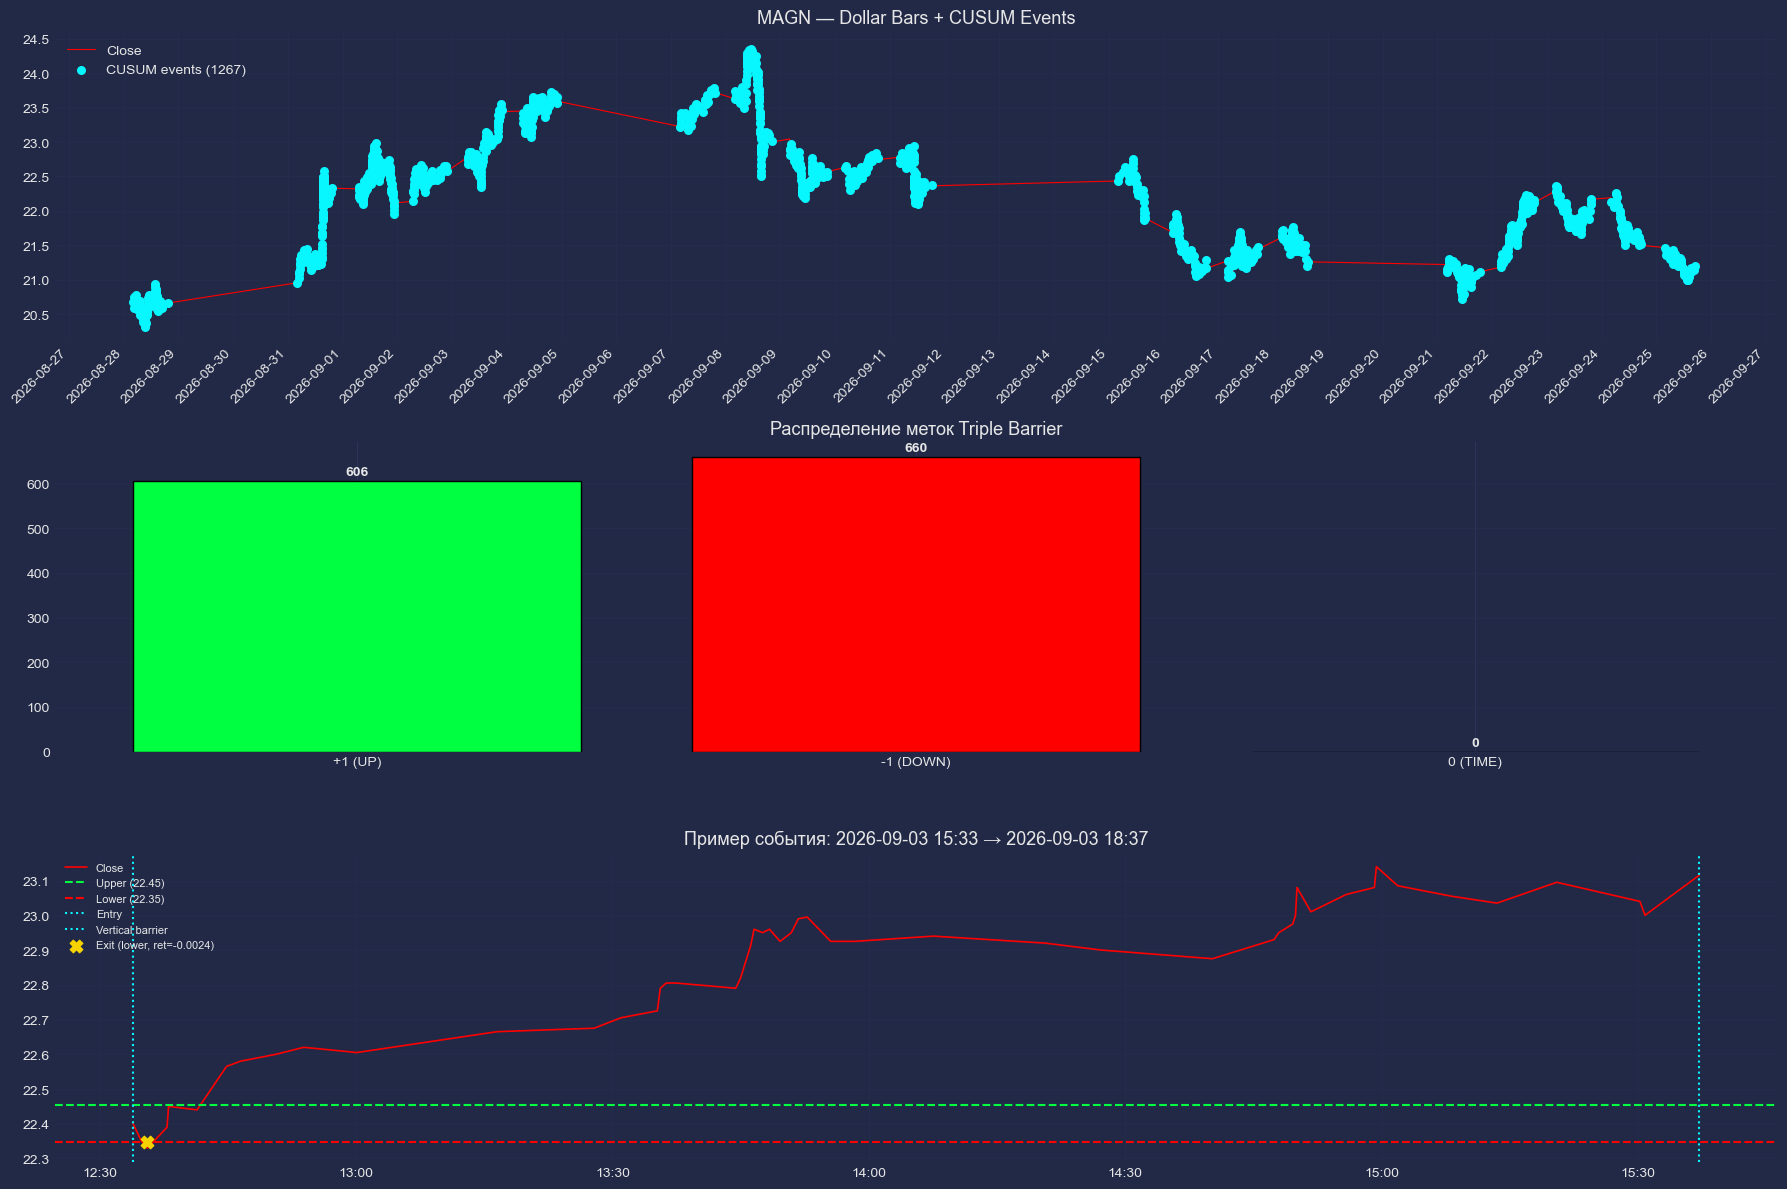

In [3]:
# ============================================================
# DOLLAR BARS + CUSUM + TRIPLE BARRIER
# ============================================================

DOLLAR_THRESHOLD = 10_000_000
CUSUM_THRESHOLD = 0.002
PT_SL = (1.0, 1.0)
VERTICAL_BARRIER = 50
TARGET_WINDOW = 45

print("=" * 70)
print(f"{TICKER} — ПОСТРОЕНИЕ DOLLAR BARS")
print("=" * 70)

# ============================================================
# 1. БЕРЕМ RAW TRADES
# ============================================================

trades = data["trades"].copy()
print(f"\nRAW TRADES: {len(trades):,} записей")
print(f"Колонки: {list(trades.columns)}")

# ============================================================
# 2. ПРОВЕРЯЕМ НЕОБХОДИМЫЕ КОЛОНКИ
# ============================================================

required_cols = ["PRICE", "QUANTITY", "VALUE", "ts"]
missing = [col for col in required_cols if col not in trades.columns]
if missing:
    raise ValueError(f"В trades.parquet отсутствуют необходимые колонки: {missing}")

# ============================================================
# 3. ПРИВОДИМ ТИПЫ
# ============================================================

trades["ts"] = pd.to_datetime(trades["ts"])
trades["PRICE"] = pd.to_numeric(trades["PRICE"], errors="coerce")
trades["QUANTITY"] = pd.to_numeric(trades["QUANTITY"], errors="coerce")
trades["VALUE"] = pd.to_numeric(trades["VALUE"], errors="coerce")

# ============================================================
# 4. УДАЛЯЕМ БИТЫЕ СДЕЛКИ
# ============================================================

before = len(trades)
trades = trades.dropna(subset=["ts", "PRICE", "QUANTITY", "VALUE"])
trades = trades[(trades["PRICE"] > 0) & (trades["QUANTITY"] > 0) & (trades["VALUE"] > 0)].copy()
after = len(trades)
print(f"\nПосле очистки: {after:,} сделок")
if before != after:
    print(f"Удалено: {before - after:,}")

# ============================================================
# 5. FORENSIC CHECK
# VALUE — реальный денежный оборот сделки.
# PRICE × QUANTITY НЕ используем как денежный оборот,
# потому что QUANTITY задан в ЛОТАХ.

price_x_quantity = (trades["PRICE"] * trades["QUANTITY"]).sum()
real_value = trades["VALUE"].sum()
print("\n" + "=" * 70)
print("TURNOVER FORENSICS")
print("=" * 70)
print(f"PRICE × QUANTITY: {price_x_quantity:,.2f} RUB")
print(f"VALUE:            {real_value:,.2f} RUB")
if price_x_quantity > 0:
    ratio = real_value / price_x_quantity
    print(f"VALUE / (PRICE × QUANTITY): {ratio:.4f}")
print("\nДля dollar bars используется именно VALUE.")

# ============================================================
# 6. ПОДГОТАВЛИВАЕМ ДАННЫЕ ДЛЯ InformationDrivenBars
# InformationDrivenBars.build_dollar() ожидает:
#     price * quantity
# Поэтому превращаем VALUE обратно в эквивалентное
# количество акций:
#     quantity_corrected = VALUE / PRICE
# Тогда:
#     PRICE × quantity_corrected
#       =
#     PRICE × (VALUE / PRICE)
#       =
#     VALUE
# Таким образом размер лота больше вообще не имеет значения.
# ============================================================

trades_for_bars = pd.DataFrame({
    "ts": trades["ts"],
    "price": trades["PRICE"],
    "quantity": trades["VALUE"] / trades["PRICE"],})
trades_for_bars = trades_for_bars.dropna(subset=["ts", "price", "quantity"])
trades_for_bars = trades_for_bars[(trades_for_bars["price"] > 0) & (trades_for_bars["quantity"] > 0)].copy()

# ============================================================
# 7. ПРОВЕРКА ПЕРЕД ПОСТРОЕНИЕМ БАРОВ
# ============================================================

reconstructed_value = (trades_for_bars["price"] * trades_for_bars["quantity"]).sum()
print("\n" + "=" * 70)
print("DOLLAR VALUE CHECK")
print("=" * 70)
print(f"Исходный VALUE:       {real_value:,.2f} RUB")
print(f"Восстановленный value:{reconstructed_value:,.2f} RUB")
relative_error = abs(reconstructed_value - real_value) / real_value
print(f"Относительная ошибка:  {relative_error:.12%}")
if relative_error > 1e-10:
    raise ValueError("КРИТИЧЕСКАЯ ОШИБКА: VALUE не восстанавливается через price × quantity.")
print("✓ VALUE корректно восстанавливается")

# ============================================================
# 8. DOLLAR BARS
# ============================================================

print("\n" + "=" * 70)
print("ПОСТРОЕНИЕ DOLLAR BARS")
print("=" * 70)
print(f"Порог: {DOLLAR_THRESHOLD:,.0f} RUB")
bar_builder = InformationDrivenBars()
dollar_bars = bar_builder.build_dollar(trades_for_bars, threshold=DOLLAR_THRESHOLD)
print(f"Получено баров: {len(dollar_bars):,}")

# ============================================================
# 9. ПРОВЕРКА ОБОРОТА DOLLAR BARS
# ============================================================

print("\n" + "=" * 70)
print("BAR FORENSICS")
print("=" * 70)
if "volume" in dollar_bars.columns:
    bars_volume = dollar_bars["volume"].sum()
    print(f"Суммарный volume bars: {bars_volume:,.2f}")
if "value" in dollar_bars.columns:
    bars_value = dollar_bars["value"].sum()
    print(f"Суммарный VALUE bars: {bars_value:,.2f}")
    print(f"Исходный VALUE:       {real_value:,.2f}")

# ============================================================
# 10. ВРЕМЕННОЙ ИНДЕКС
# ============================================================

dollar_bars["ts"] = dollar_bars["close_time"]
dollar_bars["ts"] = pd.to_datetime(dollar_bars["ts"])
if dollar_bars["ts"].dt.tz is None:
    dollar_bars["ts"] = dollar_bars["ts"].dt.tz_localize("Europe/Moscow")
dollar_bars = dollar_bars.set_index("ts").sort_index()

# ============================================================
# 11. ПЕРЕИМЕНОВАНИЕ OHLC
# ============================================================

dollar_bars = dollar_bars.rename(columns={
    "open": "OPEN",
    "high": "HIGH",
    "low": "LOW",
    "close": "CLOSE",
    "volume": "VOLUME",
})

# ============================================================
# 12. УНИКАЛЬНОСТЬ ИНДЕКСА
# ============================================================

dollar_bars = dollar_bars[~dollar_bars.index.duplicated(keep="first")]
dollar_bars = dollar_bars[~dollar_bars.index.isna()]
print(f"\nИндекс уникален: {dollar_bars.index.is_unique}")
print(f"Итого dollar bars: {len(dollar_bars):,}")

# ============================================================
# 13. CUSUM
# ============================================================

print("\n" + "=" * 70)
print("CUSUM")
print("=" * 70)
events_idx = cusum_filter(dollar_bars["CLOSE"], threshold=CUSUM_THRESHOLD)
print(f"Найдено событий до корректировки: {len(events_idx)}")

# ============================================================
# 14. СОГЛАСОВАНИЕ TIMEZONE
# ============================================================

if len(events_idx) > 0:
    if dollar_bars.index.tz is not None:
        if events_idx.tz is None:
            events_idx = events_idx.tz_localize(dollar_bars.index.tz)
        elif events_idx.tz != dollar_bars.index.tz:
            events_idx = events_idx.tz_convert(dollar_bars.index.tz)
    else:
        if events_idx.tz is not None:
            events_idx = events_idx.tz_localize(None)
    events_idx = events_idx[~events_idx.duplicated()]
    pos = dollar_bars.index.get_indexer(events_idx, method="nearest")
    events_idx = dollar_bars.index[pos]
    events_idx = events_idx[~events_idx.duplicated()]
    events_idx = events_idx.sort_values()
    print(f"После согласования: {len(events_idx)} событий")

# ============================================================
# 15. ПОДГОТОВКА К TRIPLE BARRIER
# ============================================================

bars_for_labeling = dollar_bars.rename(columns={
    "open": "OPEN",
    "high": "HIGH",
    "low": "LOW",
    "close": "CLOSE",
})

# ============================================================
# 16. TRIPLE BARRIER
# ============================================================

print("\n" + "=" * 70)
print("TRIPLE BARRIER")
print("=" * 70)
labeled = triple_barrier_labeling(
    bars=bars_for_labeling,
    events=events_idx,
    pt_sl=PT_SL,
    vertical_barrier=VERTICAL_BARRIER,
    target_window=TARGET_WINDOW,
    target_method="ewm",
)
print(f"Размечено событий: {len(labeled)}")
if not labeled.empty:
    counts = labeled["label"].value_counts()
    print("\nРаспределение меток:")
    for lbl, name, emoji in [(1, "UP (+1)", "🟢"), (-1, "DOWN (-1)", "🔴"), (0, "TIME (0)", "🟡")]:
        cnt = counts.get(lbl, 0)
        pct = 100 * cnt / len(labeled)
        print(f"{emoji} {name}: {cnt:4d} ({pct:5.1f}%)")

# ============================================================
# 17. ВИЗУАЛИЗАЦИЯ
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(18, 12))

# ------------------------------------------------------------
# График 1 — Dollar Bars + CUSUM
# ------------------------------------------------------------

ax1 = axes[0]
ax1.plot(dollar_bars.index, dollar_bars["CLOSE"], linewidth=0.8, color="C4", label="Close")
if len(events_idx) > 0:
    ax1.scatter(events_idx, dollar_bars.loc[events_idx, "CLOSE"], color="C6", s=30, zorder=5, label=f"CUSUM events ({len(events_idx)})")
ax1.set_title(f"{TICKER} — Dollar Bars + CUSUM Events", fontsize=13)
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax1.xaxis.set_major_locator(mdates.DayLocator())
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha="right")

# ------------------------------------------------------------
# График 2 — Labels
# ------------------------------------------------------------

ax2 = axes[1]
if not labeled.empty:
    colors = ["C3", "C4", "C2"]
    bars_labels = ["+1 (UP)", "-1 (DOWN)", "0 (TIME)"]
    values = [counts.get(1, 0), counts.get(-1, 0), counts.get(0, 0)]
    ax2.bar(bars_labels, values, color=colors, edgecolor="black")
    for i, v in enumerate(values):
        ax2.text(i, v + max(values) * 0.02, str(v), ha="center", fontweight="bold")
ax2.set_title("Распределение меток Triple Barrier", fontsize=13)
ax2.grid(axis="y", alpha=0.3)

# ------------------------------------------------------------
# График 3 — пример события
# ------------------------------------------------------------

ax3 = axes[2]
if not labeled.empty:
    sample = labeled.sample(1).iloc[0]
    evt_time = sample.name
    t1_time = sample["t1"]
    if not isinstance(t1_time, pd.Timestamp):
        t1_time = dollar_bars.index[t1_time] if isinstance(t1_time, int) else t1_time
    mask = (dollar_bars.index >= evt_time) & (dollar_bars.index <= t1_time)
    slice_bars = dollar_bars.loc[mask]
    ax3.plot(slice_bars.index, slice_bars["CLOSE"], linewidth=1.2, color="C4", label="Close")
    ax3.axhline(y=sample["upper"], color="C3", linestyle="--", label=f"Upper ({sample['upper']:.2f})")
    ax3.axhline(y=sample["lower"], color="C4", linestyle="--", label=f"Lower ({sample['lower']:.2f})")
    ax3.axvline(x=evt_time, color="C6", linestyle=":", label="Entry")
    ax3.axvline(x=t1_time, color="C6", linestyle=":", label="Vertical barrier")
    exit_time = sample["exit_time"]
    if not isinstance(exit_time, pd.Timestamp):
        exit_time = dollar_bars.index[exit_time] if isinstance(exit_time, int) else exit_time
    ax3.scatter(exit_time, sample["exit_price"], color="C2", s=80, zorder=5, marker="X", label=f"Exit ({sample['exit_type']}, ret={sample['ret']:+.4f})")
    ax3.set_title(f"Пример события: {evt_time.strftime('%Y-%m-%d %H:%M')} → {t1_time.strftime('%Y-%m-%d %H:%M')}", fontsize=13)
    ax3.legend(loc="upper left", fontsize=8)
    ax3.grid(True, alpha=0.3)
    ax3.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

plt.tight_layout()
plt.show()

In [4]:
"""
Ячейка 3 (исправленная): Генерация признаков + XGBoost
=======================================================
Убираем datetime-колонки, добавляем микроструктурные признаки.
"""
TRAIN_RATIO = 0.75
print("▸ Генерация признаков...")

# Приводим колонки баров к нижнему регистру (ожидается feature-модулями)
bars_lower = dollar_bars.rename(columns={"OPEN": "open", "HIGH": "high", "LOW": "low", "CLOSE": "close", "VOLUME": "volume"})

# Микроструктурные признаки
mf = MicroFeatures(spread_window=20, volatility_window=20, intensity_window=20)
bars_with_micro = mf.build_all_features(bars_lower)

# Общие признаки (техиндикаторы, лаги, скользящие)
fb = FeatureBuilder(windows=[5, 10, 20], lags=[1, 2, 3], include_micro=False)
bars_featured = fb.build_all(bars_with_micro)
print(f"  Всего колонок в расширенных барах: {bars_featured.shape[1]}")

# Удаляем нечисловые колонки (datetime, строки и т.п.)
numeric_cols = bars_featured.select_dtypes(include=[np.number]).columns
bars_featured = bars_featured[numeric_cols]
print(f"  Из них числовых: {len(numeric_cols)}")

# Прикрепляем признаки к событиям
events_df = labeled.copy()
for col in bars_featured.columns:
    events_df[f"bar_{col}"] = events_df.index.map(
        lambda t: bars_featured.loc[t, col] if t in bars_featured.index else np.nan
    )

events_df = events_df.dropna()
print(f"  Событий с полными признаками: {len(events_df)}")

# Бинарные метки
mask_bin = events_df["label"] != 0
feature_cols = [c for c in events_df.columns if c.startswith("bar_")]
X = events_df[feature_cols]
y = events_df["label"]

X_bin = X.loc[mask_bin]
y_bin = y.loc[mask_bin].map({1: 1, -1: 0})

print(f"  Бинарных событий: {len(X_bin)} (UP: {y_bin.sum()}, DOWN: {len(y_bin) - y_bin.sum()})")
split_idx = int(len(X_bin) * TRAIN_RATIO)
X_train, X_test = X_bin.iloc[:split_idx], X_bin.iloc[split_idx:]
y_train, y_test = y_bin.iloc[:split_idx], y_bin.iloc[split_idx:]
print(f"  Train: {len(X_train)}, Test: {len(X_test)}")

▸ Генерация признаков...
  Всего колонок в расширенных барах: 75
  Из них числовых: 73
  Событий с полными признаками: 1265
  Бинарных событий: 1265 (UP: 605, DOWN: 660)
  Train: 948, Test: 317


XGBoost        : Accuracy=0.4826, ROC AUC=0.4797
Random Forest  : Accuracy=0.5079, ROC AUC=0.4783
LightGBM       : Accuracy=0.5016, ROC AUC=0.5022


  File "C:\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


CatBoost       : Accuracy=0.4290, ROC AUC=0.4291

Сравнение моделей:
        Model  Accuracy  ROC AUC
     LightGBM  0.501577 0.502229
      XGBoost  0.482650 0.479697
Random Forest  0.507886 0.478344
     CatBoost  0.429022 0.429100


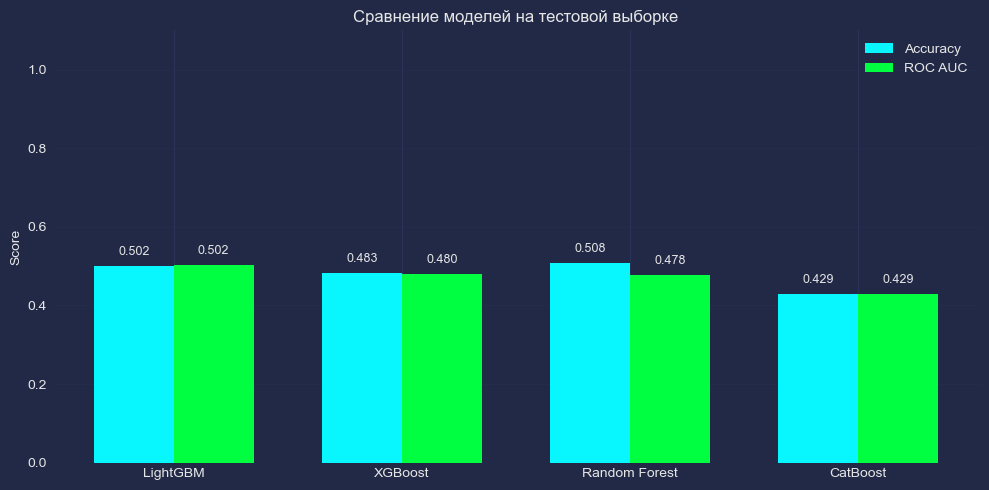

In [5]:
"""
Ячейка 4: Сравнение моделей на train/test
=========================================================
Прямое сравнение без кросс-валидации, так как данных пока мало.
"""
models = {
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=13, eval_metric="logloss", verbosity=0),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5, random_state=13, class_weight="balanced"),
    "LightGBM": LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=13, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, depth=5, learning_rate=0.05, subsample=0.8, random_seed=13, verbose=0, allow_writing_files=False),}

results = []
for name, model in models.items():
    # Проверяем, что в y_train есть оба класса, иначе модель не обучится
    if len(np.unique(y_train)) < 2:
        print(f"{name:<15}: в обучающей выборке только один класс, пропускаем")
        continue
    # Обучаем на train
    model.fit(X_train, y_train)
    # Предсказываем на test
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    # Считаем метрики (только если в y_test есть оба класса)
    if len(np.unique(y_test)) < 2:
        acc = accuracy_score(y_test, y_pred)
        print(f"{name:<15}: Accuracy={acc:.4f} (ROC AUC не определён, только один класс в тесте)")
        results.append({"Model": name, "Accuracy": acc, "ROC AUC": np.nan})
        continue
    acc = accuracy_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_proba)
    results.append({"Model": name, "Accuracy": acc, "ROC AUC": roc})
    print(f"{name:<15}: Accuracy={acc:.4f}, ROC AUC={roc:.4f}")

df_res = pd.DataFrame(results).sort_values("ROC AUC", ascending=False)
print("\nСравнение моделей:")
print(df_res.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))    
x = np.arange(len(df_res))
width = 0.35
bars1 = ax.bar(x - width/2, df_res["Accuracy"], width, label="Accuracy", color="C6")
bars2 = ax.bar(x + width/2, df_res["ROC AUC"], width, label="ROC AUC", color="C3")
    
for bar in bars1:
    height = bar.get_height()
    if not np.isnan(height):
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9)
    
for bar in bars2:
    height = bar.get_height()
    if not np.isnan(height):
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02, f'{height:.3f}', ha='center', va='bottom', fontsize=9)
    
ax.set_ylabel("Score")
ax.set_title("Сравнение моделей на тестовой выборке")
ax.set_xticks(x)
ax.set_xticklabels(df_res["Model"])
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis='y', alpha=0.3)
    
plt.tight_layout()
plt.show()

,Model,Return_%,MaxDD_%,Sharpe,ProfitFactor,WinRate_%,Trades,TP,SL,Vertical,Forced23,Reversals,Trades/day
0,XGBoost,-18.68%,-19.00%,-5.93,0.42,64.5%,293,87,201,0,0,4,36.21
1,Random Forest,-19.98%,-20.22%,-6.40,0.38,63.5%,288,103,183,0,0,1,35.59
2,LightGBM,-19.78%,-20.02%,-6.27,0.40,63.3%,294,102,188,0,0,3,36.33
3,CatBoost,-9.83%,-10.83%,-3.13,0.63,73.1%,301,59,237,0,0,4,37.20


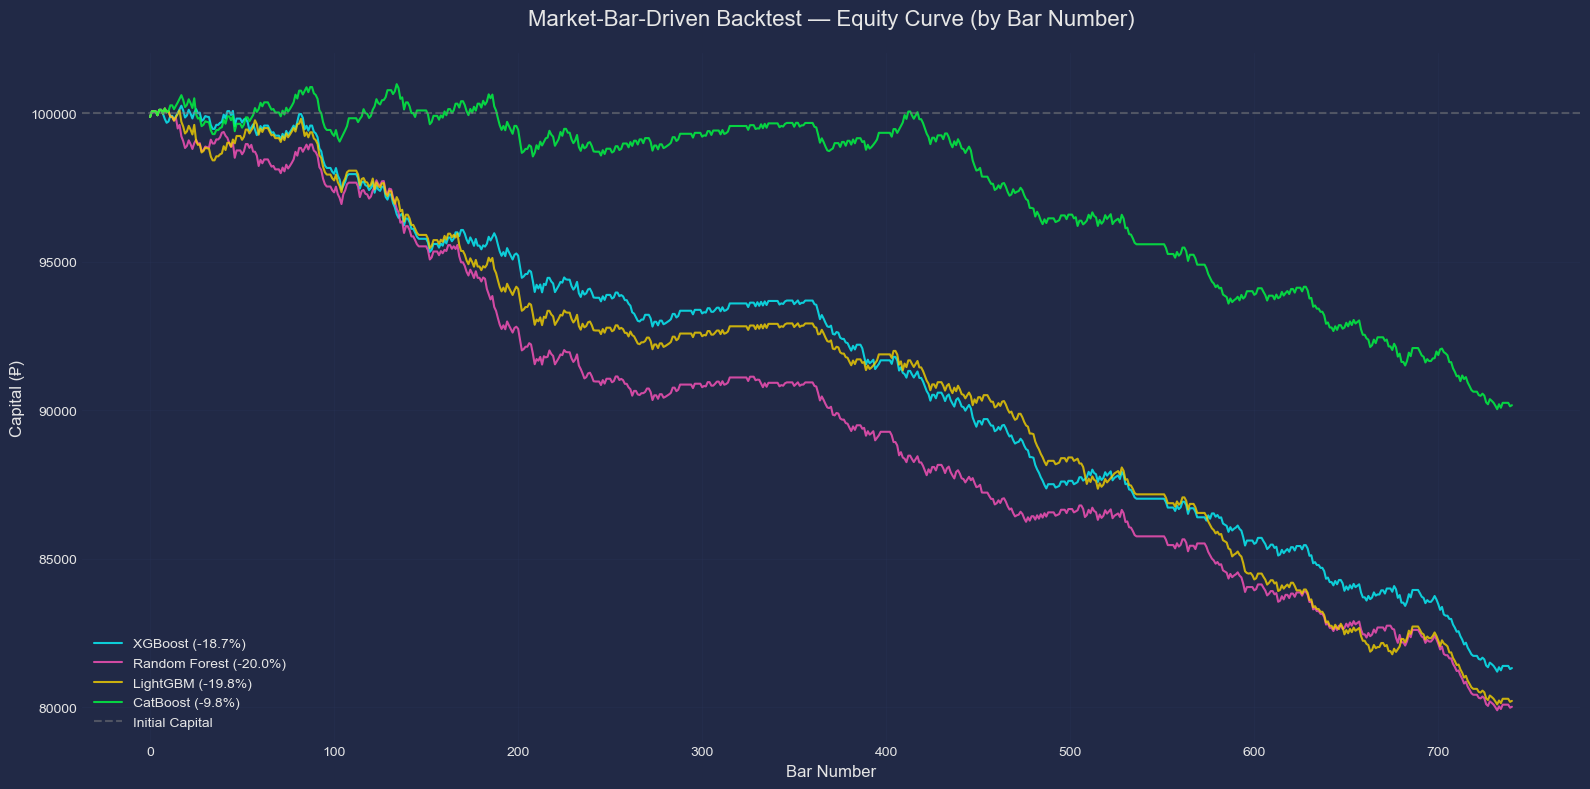

In [15]:
# =============================================================================
# MARKET-BAR-DRIVEN COMMON BACKTEST (Исправляет все архитектурные ошибки)
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INITIAL_CAPITAL = 100_000
COMMISSION = 0.0006
SLIPPAGE = 0.0001
ENTRY_CUTOFF_HOUR = 21
FORCED_CLOSE_HOUR = 23

# 1. Подготовка данных
test_indices = X_test.index
labeled_test = labeled.loc[labeled.index.isin(test_indices)].copy()
labeled_test = labeled_test[~labeled_test.index.duplicated(keep='first')]
labeled_test = labeled_test.reindex(test_indices).dropna(subset=['upper', 'lower', 't1', 'label'])

# Словарь для мгновенного поиска ML-сигнала по timestamp бара
model_classes = models[list(models.keys())[0]].classes_ if hasattr(models[list(models.keys())[0]], 'classes_') else np.unique(y_train)

def get_signals_dict(model, X_test):
    preds = model.predict(X_test)
    signals = np.where(preds == 1, 1, -1) if set(model_classes) == {0, 1} else preds
    return {idx: int(sig) for idx, sig in zip(X_test.index, signals)}

def run_bar_driven_backtest(model, X_train, y_train, X_test, labeled_test, dollar_bars,
                            initial_capital=INITIAL_CAPITAL, commission=COMMISSION, slippage=SLIPPAGE):
    model.fit(X_train, y_train)
    signals_dict = get_signals_dict(model, X_test)
    
    # Фильтруем бары только на тестовый период
    test_start = labeled_test.index.min()
    test_end = labeled_test.index.max()
    test_bars = dollar_bars.loc[test_start:test_end].copy()
    
    capital = float(initial_capital)
    equity_curve = []
    equity_times = []
    trades = []
    position = None
    
    diag = {'ml_events': len(signals_dict), 'long_signals': 0, 'short_signals': 0, 
            'signal_changes': 0, 'holds': 0, 'entries': 0, 'exits': 0, 'reversals': 0,
            'tp_exits': 0, 'sl_exits': 0, 'vertical_exits': 0, 'forced_exits': 0}
    
    prev_signal = 0
    
    def close_pos(pos, close_price, close_time, reason):
        nonlocal capital
        mult = pos['lots']
        gross = (close_price - pos['entry_price']) * mult if pos['side'] == 'long' else (pos['entry_price'] - close_price) * mult
        fees = (pos['entry_price'] * mult + close_price * mult) * commission
        pnl = gross - fees
        pnl_pct = (pnl / (pos['entry_price'] * mult) * 100) if pos['entry_price'] > 0 else 0
        
        capital += pnl
        trades.append({'entry_time': pos['entry_time'], 'exit_time': close_time, 'side': pos['side'],
                       'entry': pos['entry_price'], 'exit': close_price, 'pnl': pnl, 'pnl_pct': pnl_pct, 'exit_reason': reason})
        diag['exits'] += 1
        if reason == 'take_profit': diag['tp_exits'] += 1
        elif reason == 'stop_loss': diag['sl_exits'] += 1
        elif reason == 'vertical_barrier': diag['vertical_exits'] += 1
        elif reason == 'forced_close_23': diag['forced_exits'] += 1

    # 2. ГЛАВНЫЙ ЦИКЛ: ИДЕМ ПО КАЖДОМУ РЫНОЧНОМУ БАРУ
    for bar_time, bar in test_bars.iterrows():
        curr_close = float(bar['CLOSE'])
        curr_high = float(bar['HIGH'])
        curr_low = float(bar['LOW'])
        
        # А) ПРОВЕРКА ВЫХОДОВ ПО ПОЗИЦИИ (на каждом баре!)
        if position is not None:
            exited = False
            # 1. Stop Loss / Take Profit (консервативно: если пробиты оба, считаем что первым был SL)
            if position['side'] == 'long':
                if curr_low <= position['lower']:
                    close_pos(position, float(position['lower']), bar_time, 'stop_loss'); exited = True
                elif curr_high >= position['upper']:
                    close_pos(position, float(position['upper']), bar_time, 'take_profit'); exited = True
            else: # short
                if curr_high >= position['lower']: # для шорта lower - это SL
                    close_pos(position, float(position['lower']), bar_time, 'stop_loss'); exited = True
                elif curr_low <= position['upper']: # для шорта upper - это TP
                    close_pos(position, float(position['upper']), bar_time, 'take_profit'); exited = True
            
            # 2. Vertical Barrier
            if not exited and position['t1'] <= bar_time:
                close_pos(position, curr_close, bar_time, 'vertical_barrier'); exited = True
            
            # 3. Forced Close 23:00
            if not exited and bar_time.hour >= FORCED_CLOSE_HOUR:
                close_pos(position, curr_close, bar_time, 'forced_close_23'); exited = True
            
            if exited:
                position = None

        # Б) ОБРАБОТКА ML СИГНАЛА (если он пришел именно на этом баре)
        if bar_time in signals_dict:
            signal = signals_dict[bar_time]
            if signal == 1: diag['long_signals'] += 1
            elif signal == -1: diag['short_signals'] += 1
            
            if prev_signal != 0 and signal != prev_signal:
                diag['signal_changes'] += 1
            
            target_side = 'long' if signal == 1 else 'short'
            
            if position is None:
                # FLAT -> OPEN
                if signal != 0 and bar_time.hour < ENTRY_CUTOFF_HOUR:
                    entry_price = curr_close * (1 + slippage if signal == 1 else 1 - slippage)
                    lots = capital / entry_price
                    # Берем барьеры из labeled_test по timestamp входа
                    entry_label = labeled_test.loc[bar_time]
                    position = {
                        'side': target_side, 'entry_price': entry_price, 'entry_time': bar_time, 'lots': lots,
                        'upper': float(entry_label['upper']), 'lower': float(entry_label['lower']),
                        't1': entry_label['t1'] if isinstance(entry_label['t1'], pd.Timestamp) else pd.to_datetime(entry_label['t1'])
                    }
                    diag['entries'] += 1
            else:
                # Позиция открыта
                if position['side'] == target_side:
                    diag['holds'] += 1
                else:
                    # REVERSE: закрываем по рынку и сразу открываем новую
                    close_pos(position, curr_close, bar_time, 'reverse_signal')
                    diag['reversals'] += 1
                    
                    if bar_time.hour < ENTRY_CUTOFF_HOUR:
                        entry_price = curr_close * (1 + slippage if signal == 1 else 1 - slippage)
                        lots = capital / entry_price
                        entry_label = labeled_test.loc[bar_time]
                        position = {
                            'side': target_side, 'entry_price': entry_price, 'entry_time': bar_time, 'lots': lots,
                            'upper': float(entry_label['upper']), 'lower': float(entry_label['lower']),
                            't1': entry_label['t1'] if isinstance(entry_label['t1'], pd.Timestamp) else pd.to_datetime(entry_label['t1'])
                        }
                        diag['entries'] += 1
            
            prev_signal = signal

        # В) MARK-TO-MARKET EQUITY (для плавного графика)
        unrealized_pnl = 0
        if position is not None:
            mult = position['lots']
            unrealized_pnl = (curr_close - position['entry_price']) * mult if position['side'] == 'long' else (position['entry_price'] - curr_close) * mult
            # Вычитаем гипотетические комиссии для честного MTM
            fees = (position['entry_price'] * mult + curr_close * mult) * commission
            unrealized_pnl -= fees
            
        equity_curve.append(capital + unrealized_pnl)
        equity_times.append(bar_time)

    # Финальное закрытие, если позиция осталась открытой
    if position is not None:
        last_time = test_bars.index[-1]
        close_pos(position, float(test_bars.loc[last_time, 'CLOSE']), last_time, 'final_close')

    # 3. Расчет метрик
    df_trades = pd.DataFrame(trades)
    equity_array = np.array(equity_curve)
    total_return = (capital - initial_capital) / initial_capital * 100
    max_drawdown = ((equity_array - np.maximum.accumulate(equity_array)) / np.maximum.accumulate(equity_array)).min() * 100 if len(equity_array) > 1 else 0
    
    if not df_trades.empty:
        returns = df_trades['pnl_pct']
        sharpe = (returns.mean() / returns.std()) * np.sqrt(len(returns)) if returns.std() > 0 else 0
        win_rate = (df_trades['pnl'] > 0).mean() * 100
        profit_factor = abs(df_trades[df_trades['pnl'] > 0]['pnl'].sum() / df_trades[df_trades['pnl'] < 0]['pnl'].sum()) if (df_trades['pnl'] < 0).any() else np.inf
    else:
        sharpe = win_rate = profit_factor = 0
        
    days = max((test_end - test_start).total_seconds() / 86400, 1)
    diag['trades_per_day'] = len(trades) / days
    
    return {'total_return': total_return, 'max_drawdown': max_drawdown, 'sharpe': sharpe,
            'win_rate': win_rate, 'profit_factor': profit_factor, 'trades': df_trades,
            'equity': equity_array, 'equity_times': equity_times, 'diag': diag}

# =============================================================================
# ЗАПУСК И ВИЗУАЛИЗАЦИЯ
# =============================================================================
backtest_results = {}
for model_name, model in models.items():
    backtest_results[model_name] = run_bar_driven_backtest(model, X_train, y_train, X_test, labeled_test, dollar_bars)

# Сводная таблица
summary_data = []
for model_name, result in backtest_results.items():
    d = result['diag']
    summary_data.append({
        'Model': model_name, 'Return_%': result['total_return'], 'MaxDD_%': result['max_drawdown'],
        'Sharpe': result['sharpe'], 'ProfitFactor': result['profit_factor'], 'WinRate_%': result['win_rate'],
        'Trades': len(result['trades']), 'TP': d['tp_exits'], 'SL': d['sl_exits'], 
        'Vertical': d['vertical_exits'], 'Forced23': d['forced_exits'], 'Reversals': d['reversals'],
        'Trades/day': d['trades_per_day']
    })

df_summary = pd.DataFrame(summary_data)
display(df_summary.style
        .background_gradient(subset=['Return_%', 'ProfitFactor', 'Sharpe'], cmap='Greens')
        .background_gradient(subset=['MaxDD_%'], cmap='Reds')
        .format({'Return_%': '{:+.2f}%', 'MaxDD_%': '{:.2f}%', 'Sharpe': '{:.2f}', 'ProfitFactor': '{:.2f}',
                 'WinRate_%': '{:.1f}%', 'Trades': '{:.0f}', 'TP': '{:.0f}', 'SL': '{:.0f}', 
                 'Vertical': '{:.0f}', 'Forced23': '{:.0f}', 'Reversals': '{:.0f}', 'Trades/day': '{:.2f}'}))

# Equity Curve (ось X = номер бара/точки)
fig, ax = plt.subplots(figsize=(16, 8))
for model_name, result in backtest_results.items():
    trade_numbers = range(len(result['equity']))
    ax.plot(trade_numbers, result['equity'], label=f"{model_name} ({result['total_return']:+.1f}%)", linewidth=1.5, alpha=0.8)

ax.axhline(y=INITIAL_CAPITAL, color='gray', linestyle='--', alpha=0.5, label='Initial Capital')
ax.set_title('Market-Bar-Driven Backtest — Equity Curve (by Bar Number)', fontsize=16, pad=20)
ax.set_xlabel('Bar Number', fontsize=12)
ax.set_ylabel('Capital (₽)', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 🧪 JERICHON — Feature Lab: AlgoPack Microstructure

Это **исследовательское продолжение `jerichon_mark_42`**. Существующие ячейки и рабочий pipeline не изменяются.

Цель этого блока — раскрыть данные AlgoPack на 200% **до перехода к новым моделям**.

В текущем research уже используются:
- `MicroFeatures(...)`
- `FeatureBuilder(...)`

Поэтому ниже добавляются только отдельные группы, которые не должны дублировать уже созданные признаки.

**Важно:** новые признаки сначала рассматриваются как исследовательские. Они не добавляются автоматически в текущую ML-модель и не меняют live pipeline.

Каждая новая группа имеет:
1. 🆕 собственный блок расчёта;
2. визуализацию на выбранном тикере;
3. проверку доступности исходных данных;
4. список созданных признаков;
5. при возможности — causal alignment к существующим `dollar_bars` через backward `merge_asof`.

Для визуального исследования можно менять только `TICKER` в первой ячейке этого блока.


In [17]:
# ============================================================
# 🧪 FEATURE LAB — SETUP
# ============================================================
import re
FEATURE_LAB_TICKER = TICKER if "TICKER" in globals() else "SMLT"

print("=" * 90)
print("JERICHON FEATURE LAB")
print("=" * 90)
print(f"Тикер: {FEATURE_LAB_TICKER}")

required_raw = ["trades", "orderbook", "tradestats", "obstats", "orderstats"]
for k in required_raw:
    df = data.get(k, pd.DataFrame()) if "data" in globals() else pd.DataFrame()
    print(f"{k:<12}: {len(df):>10,} строк")

print("\nТекущая research-матрица:")
if "bars_featured" in globals():
    current_numeric = bars_featured.select_dtypes(include=[np.number]).columns.tolist()
    print(f"  текущих числовых признаков: {len(current_numeric)}")
    print("  первые признаки:", current_numeric[:20])
else:
    current_numeric = []
    print("  bars_featured ещё не создан — сначала выполни ячейки 1–5 исходного notebook.")

def _norm_col(c):
    return re.sub(r"[^a-z0-9]+", "_", str(c).lower()).strip("_")

def _prepare_ts(df):
    if df is None or df.empty or "ts" not in df.columns:
        return pd.DataFrame()
    x = df.copy()
    x["ts"] = pd.to_datetime(x["ts"], utc=True, errors="coerce").dt.tz_convert("Europe/Moscow")
    return x.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True)

def _numeric(x, col):
    return pd.to_numeric(x[col], errors="coerce")

def _find_col(df, candidates):
    """Ищет наиболее вероятную колонку по нормализованному имени."""
    if df.empty:
        return None
    norm = {_norm_col(c): c for c in df.columns}
    for cand in candidates:
        if cand in norm:
            return norm[cand]
    # мягкий поиск
    for c in df.columns:
        nc = _norm_col(c)
        for cand in candidates:
            if cand in nc:
                return c
    return None

def _find_level_col(df, side, kind, level):
    """
    Ищет wide-schema orderbook:
      bid_price_1 / ask_price_1
      bid_volume_1 / ask_volume_1
      bid_qty_1 / ask_qty_1
    """
    side = side.lower()
    if kind == "price":
        candidates = [
            f"{side}_price_{level}", f"{side}_px_{level}",
            f"{side}_p_{level}", f"{side}price{level}",
            f"{side}_price{level}", f"{side}_px{level}"
        ]
    else:
        candidates = [
            f"{side}_volume_{level}", f"{side}_qty_{level}",
            f"{side}_quantity_{level}", f"{side}_size_{level}",
            f"{side}_volume{level}", f"{side}_qty{level}",
            f"{side}_quantity{level}", f"{side}_size{level}"
        ]
    return _find_col(df, candidates)

def _plot_series(df, cols, title, ylabel=None, zero=False):
    cols = [c for c in cols if c in df.columns]
    if not cols:
        print("Нет доступных серий для визуализации.")
        return
    fig, ax = plt.subplots(figsize=(15, 6))
    for c in cols:
        ax.plot(df["ts"], df[c], label=c, linewidth=1.1)
    if zero:
        ax.axhline(0, linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Время (MSK)")
    ax.set_ylabel(ylabel or "Значение")
    ax.legend(loc="best")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

def _causal_align(feature_df, feature_cols):
    """
    Привязка новых признаков к существующим dollar bars.
    Используется только последнее известное значение <= времени бара.
    Это защищает от look-ahead при исследовании.
    """
    if "dollar_bars" not in globals() or not feature_cols:
        return pd.DataFrame()
    if dollar_bars.empty:
        return pd.DataFrame()

    bars = dollar_bars.copy()
    if isinstance(bars.index, pd.DatetimeIndex):
        bars = bars.reset_index().rename(columns={bars.index.name or "index": "ts"})
    elif "ts" not in bars.columns:
        return pd.DataFrame()

    bars["ts"] = pd.to_datetime(bars["ts"], utc=True, errors="coerce").dt.tz_convert("Europe/Moscow")
    bars = bars.dropna(subset=["ts"]).sort_values("ts")

    f = feature_df[["ts"] + [c for c in feature_cols if c in feature_df.columns]].copy()
    f["ts"] = pd.to_datetime(f["ts"], utc=True, errors="coerce").dt.tz_convert("Europe/Moscow")
    f = f.dropna(subset=["ts"]).sort_values("ts")

    return pd.merge_asof(
        bars[["ts"]].copy(),
        f,
        on="ts",
        direction="backward"
    )

def _report_group(name, feature_df, feature_cols):
    available = [c for c in feature_cols if c in feature_df.columns]
    print("\n" + "=" * 90)
    print(name)
    print("=" * 90)
    print(f"Создано признаков: {len(available)}")
    for c in available:
        s = pd.to_numeric(feature_df[c], errors="coerce")
        print(f"  {c:<36} non-null={s.notna().sum():>8,}  mean={s.mean():>12.5g}  std={s.std():>12.5g}")
    return available


JERICHON FEATURE LAB
Тикер: MAGN
trades      :    989,880 строк
orderbook   :        380 строк
tradestats  :      3,622 строк
obstats     :      3,540 строк
orderstats  :      3,655 строк

Текущая research-матрица:
  текущих числовых признаков: 73
  первые признаки: ['open', 'high', 'low', 'close', 'volume', 'value', 'count', 'rsi', 'macd', 'macd_signal', 'macd_hist', 'bb_upper', 'bb_lower', 'bb_width', 'bb_position', 'atr', 'obv', 'minute_sin', 'minute_cos', 'hour_sin']


# 🆕 ГРУППА 4 — Trade flow / Aggressor pressure

Здесь мы пытаемся получить сторону агрессивной сделки.

Приоритет:
1. использовать готовую колонку `side/aggressor`;
2. если её нет — классифицировать сделки относительно contemporaneous best bid/ask из orderbook.

Новые признаки:
- `buy_volume`
- `sell_volume`
- `delta_volume`
- `buy_ratio`
- `trade_count`
- `avg_trade_size`
- `large_trade_ratio`

**Важно:** если в raw trades нет явной стороны и нет достаточной синхронизации со стаканом, notebook не будет притворяться, что классификация точная — он сообщит об этом.


Колонки trades:
['TRADENO', 'TRADETIME', 'PRICE', 'QUANTITY', 'PERIOD', 'VALUE', 'BUYSELL', 'DECIMALS', 'TRADINGSESSION', 'TRADEDATE', 'TRADE_SESSION_DATE', 'ts', 'ticker', 'date']
Используем готовую сторону сделки: BUYSELL


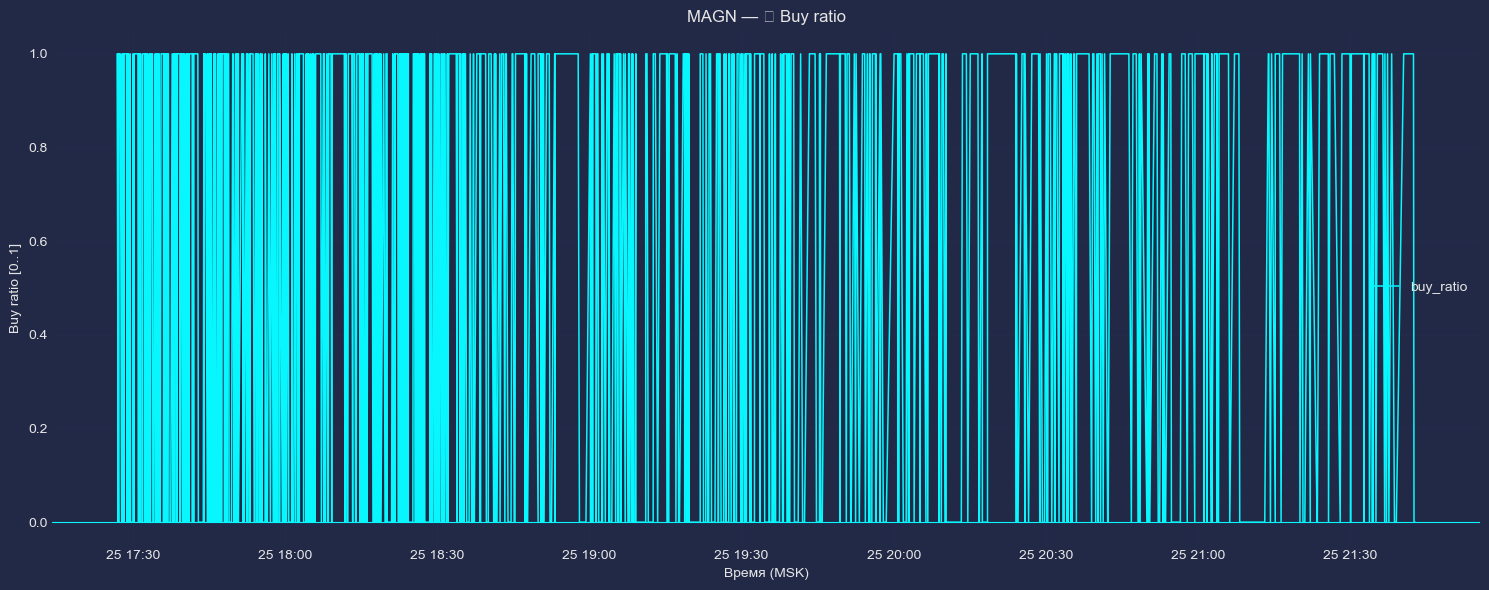

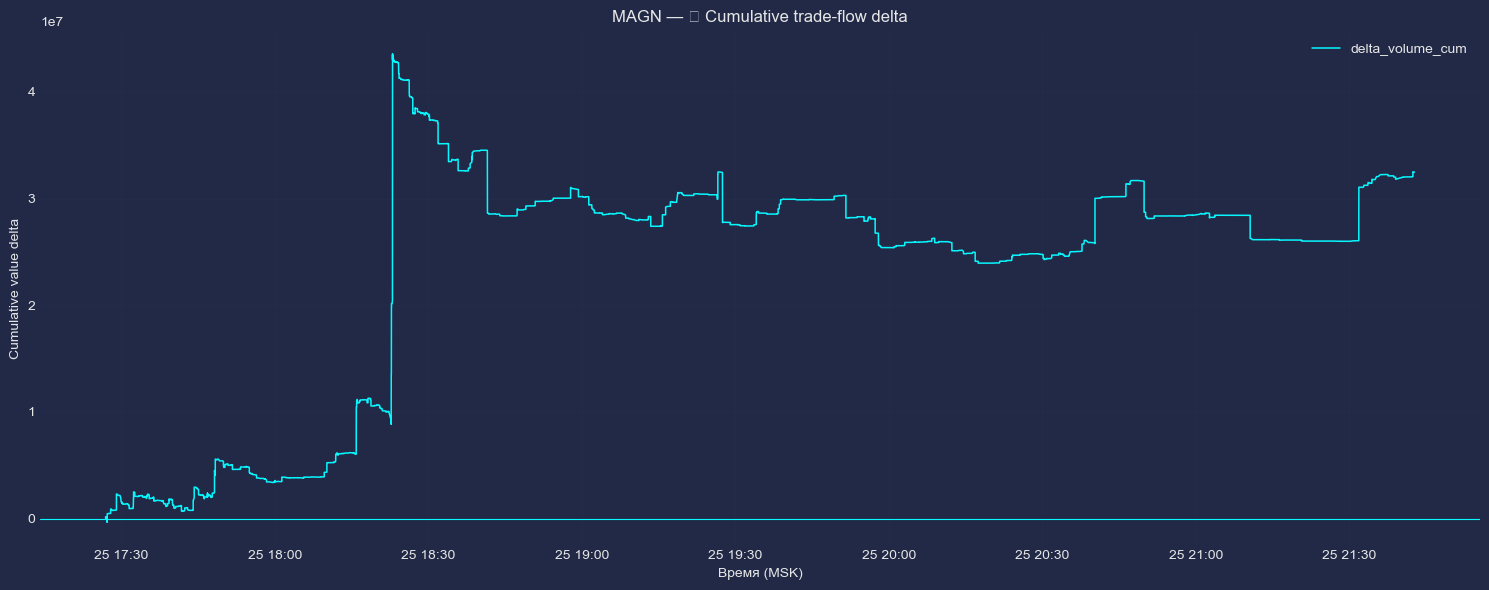


🆕 GROUP 4 — Trade flow
Создано признаков: 7
  buy_volume                           non-null= 989,880  mean=       14700  std=       82032
  sell_volume                          non-null= 989,880  mean=       15222  std=       85167
  delta_volume                         non-null= 989,880  mean=     -521.92  std=  1.2013e+05
  buy_ratio                            non-null= 989,880  mean=     0.49974  std=         0.5
  trade_count                          non-null= 989,880  mean=           1  std=           0
  avg_trade_size                       non-null= 989,880  mean=       29921  std=  1.1634e+05
  large_trade_ratio                    non-null= 989,880  mean=    0.053905  std=     0.22583


['buy_volume',
 'sell_volume',
 'delta_volume',
 'buy_ratio',
 'trade_count',
 'avg_trade_size',
 'large_trade_ratio']

In [18]:
# ============================================================
# 🆕 GROUP 4 — TRADE FLOW / AGGRESSOR PRESSURE
# ============================================================
tr = _prepare_ts(data.get("trades", pd.DataFrame()))
ob = _prepare_ts(data.get("orderbook", pd.DataFrame()))

tradeflow_df = pd.DataFrame()
tradeflow_features = []

if tr.empty:
    print("⚠️ trades пуст — группа недоступна.")
else:
    print("Колонки trades:")
    print(tr.columns.tolist())

    price_col = _find_col(tr, ["price", "trade_price", "tradeprice", "last_price"])
    qty_col = _find_col(tr, ["quantity", "qty", "volume", "size"])
    value_col = _find_col(tr, ["value", "turnover", "trade_value"])

    side_col = _find_col(tr, [
        "side", "aggressor", "aggressor_side", "direction",
        "trade_side", "buysell", "buy_sell", "initiator"
    ])

    if not price_col:
        print("⚠️ Не найдена цена сделки.")
    elif not qty_col and not value_col:
        print("⚠️ Не найден quantity/volume/value.")
    else:
        x = tr[["ts"]].copy()
        x["trade_price"] = pd.to_numeric(tr[price_col], errors="coerce")
        if value_col:
            x["trade_value"] = pd.to_numeric(tr[value_col], errors="coerce").abs()
        else:
            x["trade_value"] = (
                pd.to_numeric(tr[qty_col], errors="coerce").abs() *
                x["trade_price"]
            )

        classified = False

        # --------------------------------------------------------
        # Вариант A: готовая сторона сделки
        # --------------------------------------------------------
        if side_col:
            raw_side = tr[side_col].astype(str).str.lower().str.strip()
            buy_mask = raw_side.str.contains(r"buy|b|bid|1|куп", regex=True, na=False)
            sell_mask = raw_side.str.contains(r"sell|s|ask|-1|прод", regex=True, na=False)

            x["aggressor"] = np.select([buy_mask, sell_mask], [1, -1], default=np.nan)
            classified = x["aggressor"].notna().mean() > 0.50
            print(f"Используем готовую сторону сделки: {side_col}")
        else:
            # ----------------------------------------------------
            # Вариант B: Lee-Ready-подобная классификация по BBO
            # ----------------------------------------------------
            bid_p = _find_level_col(ob, "bid", "price", 1) if not ob.empty else None
            ask_p = _find_level_col(ob, "ask", "price", 1) if not ob.empty else None

            if bid_p and ask_p:
                q = ob[["ts"]].copy()
                q["bid"] = pd.to_numeric(ob[bid_p], errors="coerce")
                q["ask"] = pd.to_numeric(ob[ask_p], errors="coerce")
                q = q.dropna(subset=["ts", "bid", "ask"]).sort_values("ts")

                x = pd.merge_asof(
                    x.sort_values("ts"),
                    q,
                    on="ts",
                    direction="backward"
                )
                x["mid"] = (x["bid"] + x["ask"]) / 2
                x["aggressor"] = np.where(
                    x["trade_price"] >= x["ask"], 1,
                    np.where(x["trade_price"] <= x["bid"], -1, np.nan)
                )

                # Tick rule fallback for trades inside the spread.
                tick_sign = np.sign(x["trade_price"].diff()).replace(0, np.nan).ffill()
                x["aggressor"] = x["aggressor"].fillna(tick_sign)
                classified = x["aggressor"].notna().mean() > 0.50
                print("Готовой side-колонки нет: используем BBO + tick-rule fallback.")
            else:
                print("⚠️ Нет side и нет BBO — агрессорная классификация невозможна.")

        if classified:
            x["buy_volume"] = np.where(x["aggressor"] > 0, x["trade_value"], 0.0)
            x["sell_volume"] = np.where(x["aggressor"] < 0, x["trade_value"], 0.0)
            x["delta_volume"] = x["buy_volume"] - x["sell_volume"]

            x["buy_ratio"] = (
                x["buy_volume"] /
                (x["buy_volume"] + x["sell_volume"]).replace(0, np.nan)
            )

            x["trade_count"] = 1.0
            x["avg_trade_size"] = x["trade_value"]

            q95 = x["trade_value"].rolling(500, min_periods=50).quantile(0.95)
            x["large_trade_ratio"] = (x["trade_value"] >= q95).astype(float)

            tradeflow_df = x.sort_values("ts")
            tradeflow_features = [
                "buy_volume", "sell_volume", "delta_volume",
                "buy_ratio", "trade_count", "avg_trade_size",
                "large_trade_ratio"
            ]

            # Визуализация в окне 50 наблюдений/сделок — чтобы не скрывать структуру.
            plot_x = tradeflow_df.tail(min(len(tradeflow_df), 5000)).copy()
            plot_x["delta_volume_cum"] = plot_x["delta_volume"].cumsum()

            _plot_series(
                plot_x,
                ["buy_ratio"],
                f"{FEATURE_LAB_TICKER} — 🆕 Buy ratio",
                ylabel="Buy ratio [0..1]",
                zero=True
            )

            _plot_series(
                plot_x,
                ["delta_volume_cum"],
                f"{FEATURE_LAB_TICKER} — 🆕 Cumulative trade-flow delta",
                ylabel="Cumulative value delta",
                zero=True
            )

_report_group("🆕 GROUP 4 — Trade flow", tradeflow_df, tradeflow_features)



# 🚀 JERICHON Feature Lab v2 — Exact AlgoPack exploitation

После диагностики структуры AlgoPack мы больше не угадываем названия колонок.

Подтверждено:

- `tradestats`: 23 числовых поля;
- `obstats`: 17 числовых полей;
- `orderstats`: 22 числовых поля;
- `orderbook`: 20 строк на дневной snapshot, 10 bid + 10 ask.

Особенно важно: `obstats`, `orderstats` и `tradestats` имеют собственные временные ряды примерно с шагом 5 минут. Поэтому их можно **каузально** присоединять к dollar bars через `merge_asof(direction="backward")`.

`orderbook.parquet` — другой случай: диагностика показывает только один snapshot из 20 уровней на файл/день. Его нельзя распространять на весь торговый день как будто это исторический стакан. Поэтому в этой версии он используется для визуальной проверки и snapshot-признаков, но **не попадает в историческую модельную матрицу как полноценный intraday order-book feed**.

Главная цель этой версии:

> не просто добавить ещё много колонок, а превратить уже существующие AlgoPack supercandles в содержательные признаки: pressure, liquidity, cancellation, execution quality, VWAP displacement, dynamics и multi-timescale state.

Модели здесь НЕ меняются.


In [19]:
# ============================================================
# 🔧 V2 SETUP — exact AlgoPack schema
# ============================================================
FEATURE_LAB_TICKER = TICKER  # "SMLT"

def _prep_exact(df):
    """Копия DataFrame + строгая нормализация ts."""
    if df is None or not isinstance(df, pd.DataFrame) or df.empty:
        return pd.DataFrame()

    x = df.copy()

    if "ts" not in x.columns:
        return pd.DataFrame()

    x["ts"] = pd.to_datetime(x["ts"], errors="coerce")

    # Все numeric-поля переводим в numeric без изменения исходных объектов.
    for c in x.columns:
        if c not in {"ts", "ticker", "secid", "super_kind", "date", "SYSTIME"}:
            x[c] = pd.to_numeric(x[c], errors="coerce")

    return x.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True)


def _safe_div(a, b, eps=1e-12):
    return a / (b.abs() + eps)


def _imb(a, b, eps=1e-12):
    return (a - b) / (a + b).abs().add(eps)


def _add_dyn(df, cols, windows=(3, 6, 12, 24)):
    """Добавляет causal rolling mean/std/z-score и delta."""
    out = df.copy()

    for c in cols:
        if c not in out.columns:
            continue

        s = pd.to_numeric(out[c], errors="coerce")

        out[f"{c}_chg"] = s.diff()
        out[f"{c}_ret"] = s.pct_change().replace([np.inf, -np.inf], np.nan)

        for w in windows:
            minp = max(2, min(w, 3))
            mean = s.rolling(w, min_periods=minp).mean()
            std = s.rolling(w, min_periods=minp).std()

            out[f"{c}_ma{w}"] = mean
            out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)

    return out

def _prepare_ts(df: pd.DataFrame) -> pd.DataFrame:
    """Нормализует колонку ts: datetime + Europe/Moscow + сортировка."""
    if df is None or df.empty:
        return pd.DataFrame()
    
    out = df.copy()
    
    if "ts" not in out.columns:
        return out
    
    out["ts"] = pd.to_datetime(out["ts"], errors="coerce")
    
    if out["ts"].dt.tz is None:
        out["ts"] = out["ts"].dt.tz_localize("Europe/Moscow")
    else:
        out["ts"] = out["ts"].dt.tz_convert("Europe/Moscow")
    
    out = out.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True)
    return out

feature_v2_groups = {}
feature_v2_frames = {}

print("Feature Lab v2 initialized.")
print("Exact sources:", list(data.keys()) if "data" in globals() else "data not found")


Feature Lab v2 initialized.
Exact sources: ['candles', 'trades', 'orderbook', 'tradestats', 'obstats', 'orderstats']



## 🆕 GROUP 10 — `tradestats`: signed execution / price-discovery pressure

Здесь уже не нужно реконструировать aggressor side из отдельных trades: AlgoPack сам предоставляет:

- `trades_b / trades_s`;
- `vol_b / vol_s`;
- `val_b / val_s`;
- `disb`;
- `pr_vwap_b / pr_vwap_s`;
- `pr_std`;
- `pr_change`.

Это очень сильный источник для текущей задачи, потому что он уже агрегирован и синхронизирован по времени.

Создаём не копии исходных колонок, а отношения и pressure-признаки:
- count imbalance;
- volume imbalance;
- value imbalance;
- buy/sell activity share;
- VWAP pressure;
- VWAP displacement;
- volatility × order-flow interaction;
- activity intensity.


In [20]:

# ============================================================
# 🆕 GROUP 10 — TRADESTATS PRESSURE
# ============================================================

ts0 = _prep_exact(data.get("tradestats"))

if ts0.empty:
    print("❌ tradestats empty")
else:
    tsf = ts0[["ts"]].copy()

    # Базовые pressure metrics.
    tsf["ts_trade_imbalance"] = _imb(ts0["trades_b"], ts0["trades_s"])
    tsf["ts_volume_imbalance"] = _imb(ts0["vol_b"], ts0["vol_s"])
    tsf["ts_value_imbalance"] = _imb(ts0["val_b"], ts0["val_s"])

    tsf["ts_buy_trade_share"] = _safe_div(
        ts0["trades_b"], ts0["trades_b"] + ts0["trades_s"]
    )
    tsf["ts_buy_volume_share"] = _safe_div(
        ts0["vol_b"], ts0["vol_b"] + ts0["vol_s"]
    )
    tsf["ts_buy_value_share"] = _safe_div(
        ts0["val_b"], ts0["val_b"] + ts0["val_s"]
    )

    # VWAP pressure: buy VWAP vs sell VWAP.
    tsf["ts_vwap_b_s_diff"] = ts0["pr_vwap_b"] - ts0["pr_vwap_s"]
    tsf["ts_vwap_b_s_bps"] = (
        (ts0["pr_vwap_b"] - ts0["pr_vwap_s"])
        / ((ts0["pr_vwap_b"] + ts0["pr_vwap_s"]) / 2 + 1e-12)
        * 1e4
    )

    # Buy/sell VWAP относительно общего VWAP.
    tsf["ts_buy_vwap_displacement"] = (
        ts0["pr_vwap_b"] - ts0["pr_vwap"]
    ) / (ts0["pr_vwap"] + 1e-12)

    tsf["ts_sell_vwap_displacement"] = (
        ts0["pr_vwap_s"] - ts0["pr_vwap"]
    ) / (ts0["pr_vwap"] + 1e-12)

    # Activity / intensity.
    tsf["ts_value_per_trade"] = _safe_div(ts0["val"], ts0["trades"])
    tsf["ts_volume_per_trade"] = _safe_div(ts0["vol"], ts0["trades"])

    # Реализованное изменение × flow.
    tsf["ts_flow_x_return"] = ts0["disb"] * ts0["pr_change"]
    tsf["ts_flow_x_volatility"] = ts0["disb"] * ts0["pr_std"]

    # Не копируем весь исходный tradestats:
    # эти признаки — именно derived candidates.
    dyn_cols = [
        "ts_trade_imbalance",
        "ts_volume_imbalance",
        "ts_value_imbalance",
        "ts_buy_volume_share",
        "ts_buy_value_share",
        "ts_vwap_b_s_bps",
        "ts_value_per_trade",
        "ts_flow_x_return",
    ]

    tsf = _add_dyn(tsf, dyn_cols, windows=(3, 6, 12, 24))

    feature_v2_groups["tradestats_pressure"] = [
        c for c in tsf.columns if c != "ts"
    ]
    feature_v2_frames["tradestats_pressure"] = tsf

    print(f"✅ tradestats pressure: {len(feature_v2_groups['tradestats_pressure'])} candidates")

    display(tsf.tail(10))


✅ tradestats pressure: 94 candidates


,ts,ts_trade_imbalance,ts_volume_imbalance,ts_value_imbalance,ts_buy_trade_share,ts_buy_volume_share,ts_buy_value_share,ts_vwap_b_s_diff,ts_vwap_b_s_bps,ts_buy_vwap_displacement,...,ts_flow_x_return_chg,ts_flow_x_return_ret,ts_flow_x_return_ma3,ts_flow_x_return_z3,ts_flow_x_return_ma6,ts_flow_x_return_z6,ts_flow_x_return_ma12,ts_flow_x_return_z12,ts_flow_x_return_ma24,ts_flow_x_return_z24
3612,2026-09-25 20:55:00+03:00,0.000000,-0.406931,-0.406609,0.500000,0.296535,0.296696,0.016,7.548594,0.000519,...,0.034456,-2.281250,0.016520,0.093443,0.017857,0.056377,0.046029,-0.360258,0.040631,-0.295526
3613,2026-09-25 21:00:00+03:00,0.130435,0.502973,0.503148,0.565217,0.751486,0.751574,0.010,4.715869,0.000094,...,0.004248,0.219512,0.009283,0.674518,0.021791,0.072250,0.031554,-0.140169,0.041614,-0.251651
3614,2026-09-25 21:05:00+03:00,0.163636,-0.023917,-0.023660,0.581818,0.488042,0.488170,0.011,5.186600,0.000283,...,-0.024542,-1.039915,0.014003,-1.139460,0.020768,-0.836172,0.016225,-0.549867,0.035859,-0.532762
3615,2026-09-25 21:10:00+03:00,0.090909,0.533333,0.533553,0.545455,0.766667,0.766777,0.009,4.243582,0.000094,...,-0.024021,25.500000,-0.000768,-0.996405,0.007876,-1.247510,0.014007,-1.172720,0.037068,-0.916608
3616,2026-09-25 21:15:00+03:00,-0.841270,-0.981581,-0.981566,0.079365,0.009209,0.009217,0.018,8.492168,0.000802,...,0.001835,-0.073509,-0.016344,-0.507367,-0.003531,-0.925109,0.004921,-1.083912,0.036932,-0.885881
3617,2026-09-25 21:20:00+03:00,0.333333,-0.569061,-0.568883,0.666667,0.215470,0.215558,0.011,5.189781,0.000425,...,-0.003776,0.163265,-0.024998,-1.009225,-0.005497,-0.932855,0.002679,-1.077321,0.037309,-0.952738
3618,2026-09-25 21:25:00+03:00,-0.400000,-0.960159,-0.960159,0.300000,0.019920,0.019921,0.005,2.358212,0.000236,...,-0.018408,0.684211,-0.031781,-1.139998,-0.016275,-1.204938,0.000791,-1.535761,0.035421,-1.168317
3619,2026-09-25 21:30:00+03:00,0.777778,-0.403974,-0.403886,0.888889,0.298013,0.298057,0.005,2.358212,0.000189,...,0.045312,-1.000000,-0.024072,1.056329,-0.020208,1.172310,0.000791,-0.026358,0.034042,-0.489966
3620,2026-09-25 21:35:00+03:00,0.813953,0.963658,0.963656,0.906977,0.981829,0.981828,-0.001,-0.470910,0.000000,...,0.158496,NaN,0.037728,1.128526,0.006365,2.004053,0.013567,2.653850,0.037442,1.645979
3621,2026-09-25 21:40:00+03:00,-0.555556,0.024146,0.024491,0.222222,0.512073,0.512245,0.015,7.066305,0.000330,...,-0.158496,-1.000000,0.052832,-0.577350,0.010525,-0.141237,0.009201,-0.172608,0.029168,-0.446400


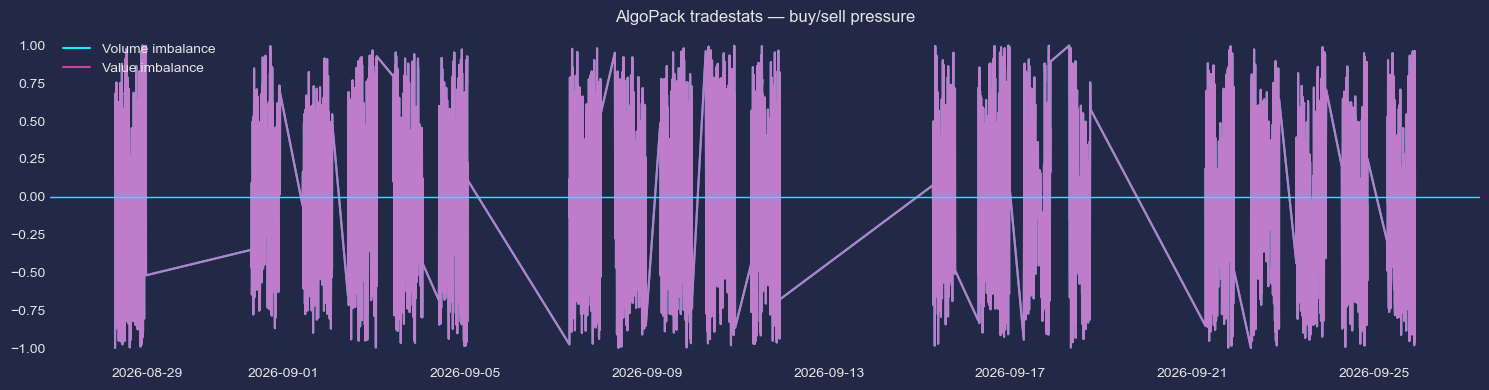

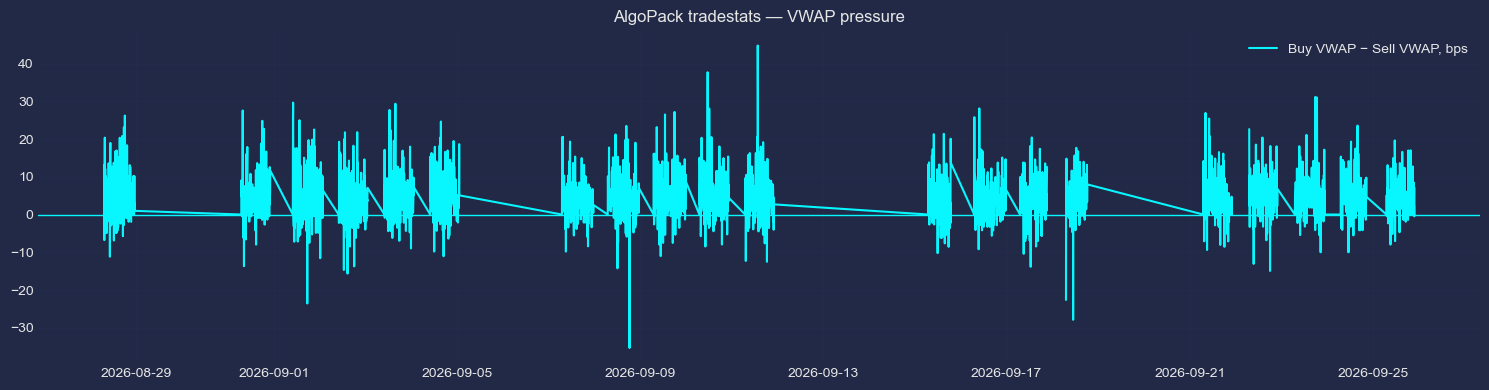

In [21]:

# ============================================================
# 📈 GROUP 10 VISUALIZATION
# ============================================================

if "tsf" in globals() and not tsf.empty:
    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(tsf["ts"], tsf["ts_volume_imbalance"], label="Volume imbalance")
    ax.plot(tsf["ts"], tsf["ts_value_imbalance"], label="Value imbalance", alpha=0.75)
    ax.axhline(0, linewidth=1)
    ax.set_title("AlgoPack tradestats — buy/sell pressure")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(tsf["ts"], tsf["ts_vwap_b_s_bps"], label="Buy VWAP − Sell VWAP, bps")
    ax.axhline(0, linewidth=1)
    ax.set_title("AlgoPack tradestats — VWAP pressure")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()



## 🆕 GROUP 11 — `orderstats`: placement vs cancellation pressure

Теперь используем точную структуру.

`put_*` — поток выставленных заявок, отдельно bid/ask.

`cancel_*` — поток снятых заявок, отдельно bid/ask.

Это позволяет построить более интересную картину:

**1. Placement pressure**
- куда выставляют новые заявки;
- какая сторона получает больше объёма/стоимости.

**2. Cancellation pressure**
- какая сторона активнее снимает ликвидность.

**3. Cancellation / placement ratio**
- насколько быстро отмены сопоставимы с новыми заявками.

**4. Net liquidity pressure**
- placement minus cancellation;
- отдельно по bid/ask;
- imbalance net flow.

**5. VWAP of placement/cancellation**
- где относительно рынка размещаются/снимаются объёмы.

Это существенно информативнее одного общего `cancel_pressure`.


In [22]:

# ============================================================
# 🆕 GROUP 11 — ORDERSTATS
# ============================================================

os0 = _prep_exact(data.get("orderstats"))

if os0.empty:
    print("❌ orderstats empty")
else:
    osf = os0[["ts"]].copy()

    # Placement.
    osf["os_put_orders_imb"] = _imb(os0["put_orders_b"], os0["put_orders_s"])
    osf["os_put_volume_imb"] = _imb(os0["put_vol_b"], os0["put_vol_s"])
    osf["os_put_value_imb"] = _imb(os0["put_val_b"], os0["put_val_s"])

    osf["os_put_buy_share"] = _safe_div(
        os0["put_vol_b"], os0["put_vol_b"] + os0["put_vol_s"]
    )
    osf["os_put_value_buy_share"] = _safe_div(
        os0["put_val_b"], os0["put_val_b"] + os0["put_val_s"]
    )

    # Cancellation.
    osf["os_cancel_orders_imb"] = _imb(
        os0["cancel_orders_b"], os0["cancel_orders_s"]
    )
    osf["os_cancel_volume_imb"] = _imb(
        os0["cancel_vol_b"], os0["cancel_vol_s"]
    )
    osf["os_cancel_value_imb"] = _imb(
        os0["cancel_val_b"], os0["cancel_val_s"]
    )

    osf["os_cancel_buy_share"] = _safe_div(
        os0["cancel_vol_b"], os0["cancel_vol_b"] + os0["cancel_vol_s"]
    )

    # Cancellation / placement ratios.
    osf["os_cancel_to_put_orders"] = _safe_div(
        os0["cancel_orders"], os0["put_orders"]
    )
    osf["os_cancel_to_put_volume"] = _safe_div(
        os0["cancel_vol"], os0["put_vol"]
    )
    osf["os_cancel_to_put_value"] = _safe_div(
        os0["cancel_val"], os0["put_val"]
    )

    # Net flow = newly placed - cancelled.
    osf["os_net_orders"] = os0["put_orders"] - os0["cancel_orders"]
    osf["os_net_volume"] = os0["put_vol"] - os0["cancel_vol"]
    osf["os_net_value"] = os0["put_val"] - os0["cancel_val"]

    osf["os_net_volume_imb"] = _imb(
        os0["put_vol_b"] - os0["cancel_vol_b"],
        os0["put_vol_s"] - os0["cancel_vol_s"]
    )

    osf["os_net_value_imb"] = _imb(
        os0["put_val_b"] - os0["cancel_val_b"],
        os0["put_val_s"] - os0["cancel_val_s"]
    )

    # Placement VWAP pressure.
    osf["os_put_vwap_b_s_bps"] = (
        (os0["put_vwap_b"] - os0["put_vwap_s"])
        / ((os0["put_vwap_b"] + os0["put_vwap_s"]) / 2 + 1e-12)
        * 1e4
    )

    # Cancellation VWAP pressure.
    osf["os_cancel_vwap_b_s_bps"] = (
        (os0["cancel_vwap_b"] - os0["cancel_vwap_s"])
        / ((os0["cancel_vwap_b"] + os0["cancel_vwap_s"]) / 2 + 1e-12)
        * 1e4
    )

    # Where cancellation happens relative to placement.
    osf["os_cancel_vs_put_vwap_b"] = (
        os0["cancel_vwap_b"] - os0["put_vwap_b"]
    ) / (os0["put_vwap_b"] + 1e-12)

    osf["os_cancel_vs_put_vwap_s"] = (
        os0["cancel_vwap_s"] - os0["put_vwap_s"]
    ) / (os0["put_vwap_s"] + 1e-12)

    dyn_cols = [
        "os_put_orders_imb",
        "os_put_volume_imb",
        "os_put_value_imb",
        "os_cancel_orders_imb",
        "os_cancel_volume_imb",
        "os_cancel_value_imb",
        "os_cancel_to_put_orders",
        "os_cancel_to_put_volume",
        "os_cancel_to_put_value",
        "os_net_volume",
        "os_net_value",
        "os_net_volume_imb",
        "os_net_value_imb",
        "os_put_vwap_b_s_bps",
        "os_cancel_vwap_b_s_bps",
    ]

    osf = _add_dyn(osf, dyn_cols, windows=(3, 6, 12, 24))

    feature_v2_groups["orderstats_pressure"] = [
        c for c in osf.columns if c != "ts"
    ]
    feature_v2_frames["orderstats_pressure"] = osf

    print(f"✅ orderstats pressure: {len(feature_v2_groups['orderstats_pressure'])} candidates")

    display(osf.tail(10))


✅ orderstats pressure: 171 candidates


,ts,os_put_orders_imb,os_put_volume_imb,os_put_value_imb,os_put_buy_share,os_put_value_buy_share,os_cancel_orders_imb,os_cancel_volume_imb,os_cancel_value_imb,os_cancel_buy_share,...,os_cancel_vwap_b_s_bps_chg,os_cancel_vwap_b_s_bps_ret,os_cancel_vwap_b_s_bps_ma3,os_cancel_vwap_b_s_bps_z3,os_cancel_vwap_b_s_bps_ma6,os_cancel_vwap_b_s_bps_z6,os_cancel_vwap_b_s_bps_ma12,os_cancel_vwap_b_s_bps_z12,os_cancel_vwap_b_s_bps_ma24,os_cancel_vwap_b_s_bps_z24
3645,2026-09-25 20:55:00+03:00,0.091304,0.288967,0.292681,0.644484,0.646340,0.069212,0.284291,0.280388,0.642146,...,-3.857959,0.047549,-84.311500,-0.235674,-74.039932,-0.742830,-77.932027,-0.538644,-91.620928,0.093221
3646,2026-09-25 21:00:00+03:00,0.034483,0.166519,0.161994,0.583260,0.580997,-0.044586,0.151454,0.145800,0.575727,...,-30.258134,0.356004,-93.793920,-1.148529,-79.787740,-1.572780,-82.139302,-2.040161,-78.909654,-2.496886
3647,2026-09-25 21:05:00+03:00,0.179832,0.412125,0.408833,0.706062,0.704417,0.172816,0.425606,0.422735,0.712803,...,45.411025,-0.394015,-90.028942,0.873166,-82.455480,0.642911,-81.891900,0.734489,-78.189988,0.573468
3648,2026-09-25 21:10:00+03:00,0.221790,0.441234,0.438767,0.720617,0.719383,0.243902,0.439921,0.437418,0.719960,...,7.585629,-0.108613,-82.449436,0.704611,-83.380468,1.157737,-79.213757,1.009466,-78.220100,1.099230
3649,2026-09-25 21:15:00+03:00,0.230392,0.290646,0.291179,0.645323,0.645590,0.175439,0.328803,0.325853,0.664401,...,-3.832272,0.061557,-66.061308,-0.006935,-79.927614,0.713642,-77.634555,0.675643,-78.232717,0.836876
3650,2026-09-25 21:20:00+03:00,0.181495,0.417641,0.416754,0.708820,0.708377,0.092105,0.234876,0.228343,0.617438,...,-72.122240,1.091313,-88.850936,-1.153542,-89.439939,-1.585146,-82.217121,-2.286059,-81.094727,-3.030645
3651,2026-09-25 21:25:00+03:00,0.223529,0.329113,0.337328,0.664557,0.668664,0.218543,0.326388,0.323043,0.663194,...,63.169147,-0.457052,-93.112724,0.459719,-87.781080,0.406808,-80.910506,0.240404,-79.849554,0.264537
3652,2026-09-25 21:30:00+03:00,0.154362,0.652521,0.651181,0.826261,0.825591,0.056000,0.598900,0.596820,0.799450,...,10.498742,-0.139907,-92.597508,0.704051,-79.329408,0.506558,-79.558574,0.603802,-79.522693,0.814715
3653,2026-09-25 21:35:00+03:00,0.368715,0.579523,0.563567,0.789762,0.781784,0.420063,0.625329,0.622636,0.812665,...,-24.020312,0.372166,-76.048315,-1.039209,-82.449626,-0.210965,-82.452553,-0.258971,-80.252667,-0.451998
3654,2026-09-25 21:40:00+03:00,0.223881,0.369173,0.374082,0.684586,0.687041,0.189655,0.398013,0.393946,0.699006,...,-7.587038,0.085669,-83.084518,-0.791791,-88.098621,-0.292566,-85.739545,-0.464796,-81.464053,-0.796555


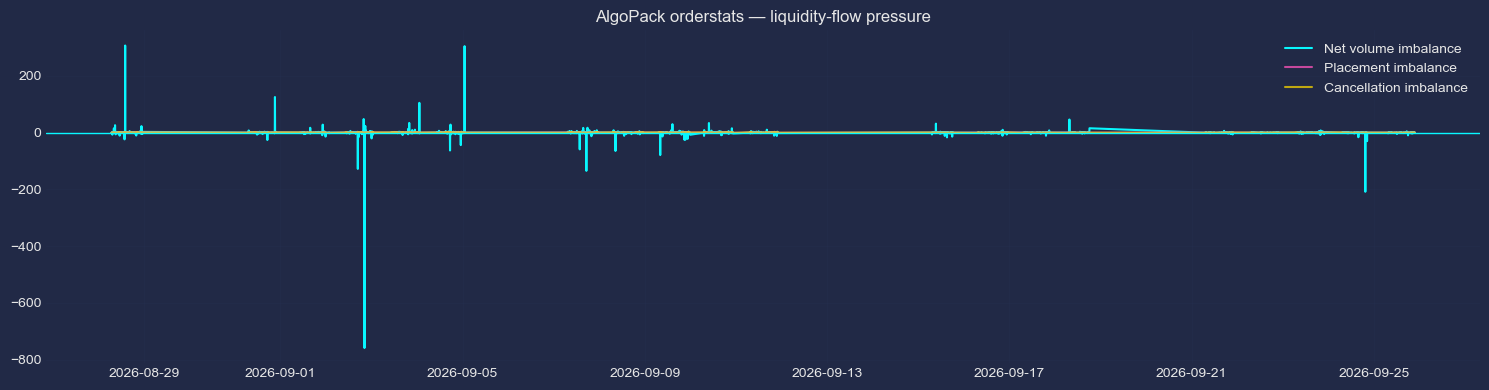

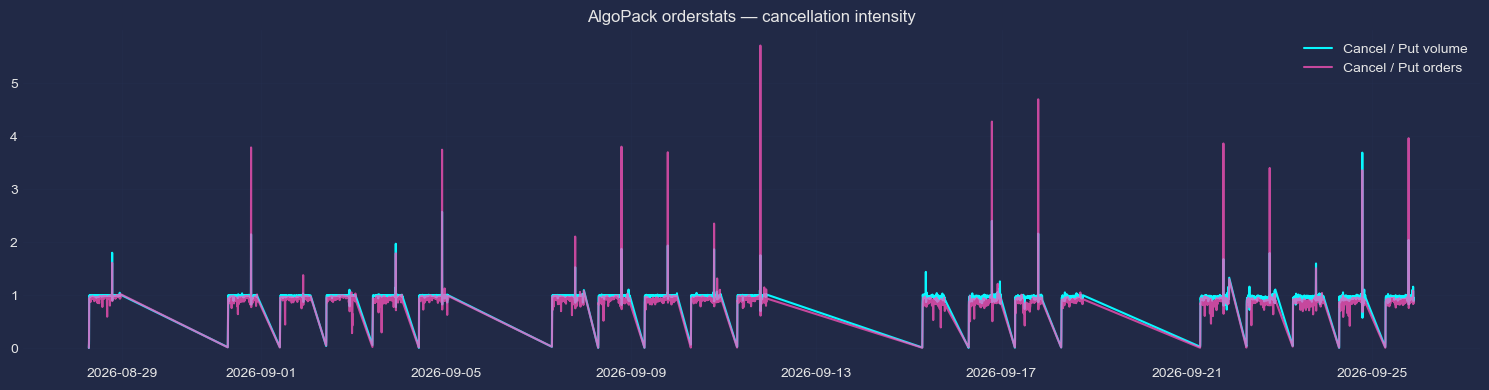

In [23]:

# ============================================================
# 📈 GROUP 11 VISUALIZATION
# ============================================================

if "osf" in globals() and not osf.empty:
    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(osf["ts"], osf["os_net_volume_imb"], label="Net volume imbalance")
    ax.plot(osf["ts"], osf["os_put_volume_imb"], label="Placement imbalance", alpha=0.75)
    ax.plot(osf["ts"], osf["os_cancel_volume_imb"], label="Cancellation imbalance", alpha=0.75)
    ax.axhline(0, linewidth=1)
    ax.set_title("AlgoPack orderstats — liquidity-flow pressure")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(osf["ts"], osf["os_cancel_to_put_volume"], label="Cancel / Put volume")
    ax.plot(osf["ts"], osf["os_cancel_to_put_orders"], label="Cancel / Put orders", alpha=0.75)
    ax.set_title("AlgoPack orderstats — cancellation intensity")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()



## 🆕 GROUP 12 — `obstats`: liquidity topology

Здесь AlgoPack уже делает за нас то, что мы хотели получить из стакана.

Особенно ценные поля:

- `spread_bbo`;
- `spread_lv10`;
- `spread_1mio`;
- `levels_b / levels_s`;
- `vol_b / vol_s`;
- `val_b / val_s`;
- `imbalance_vol_bbo`;
- `imbalance_val_bbo`;
- `imbalance_vol`;
- `imbalance_val`;
- `vwap_b / vwap_s`;
- `vwap_b_1mio / vwap_s_1mio`.

Добавляем признаки, описывающие не просто «кто сильнее», а **форму ликвидности**:

- depth imbalance;
- liquidity concentration;
- spread expansion;
- BBO vs L10 spread ratio;
- 1M RUB liquidity cost proxy;
- distance between buy/sell VWAP;
- current price displacement относительно book VWAP;
- asymmetry между BBO и глубокой ликвидностью.


In [24]:
# ============================================================
# 🆕 GROUP 12 — OBSTATS TOPOLOGY (исправленная версия)
# ============================================================

obs = _prepare_ts(data.get("obstats", pd.DataFrame()))
obstats_df = pd.DataFrame()
obstats_features = []

if obs.empty:
    print("⚠️ obstats пуст — группа недоступна.")
else:
    print("Колонки obstats:")
    print(obs.columns.tolist())
    
    # Базовые признаки из obstats
    obs0 = obs.copy()
    obsf = pd.DataFrame({"ts": obs0["ts"]})
    
    # Volume/value totals
    obsf["ob_total_volume"] = obs0["vol_b"].fillna(0) + obs0["vol_s"].fillna(0)
    obsf["ob_total_value"] = obs0["val_b"].fillna(0) + obs0["val_s"].fillna(0)
    
    # Imbalance: BBO vs deep
    obsf["ob_vol_imb_bbo_vs_deep"] = (
        obs0["imbalance_vol_bbo"] - obs0["imbalance_vol"]
    )
    obsf["ob_val_imb_bbo_vs_deep"] = (
        obs0["imbalance_val_bbo"] - obs0["imbalance_val"]
    )
    
    # Depth concentration proxies
    obsf["ob_bid_value_share"] = obs0["val_b"] / (obs0["val_b"] + obs0["val_s"] + 1e-12)
    obsf["ob_bid_volume_share"] = obs0["vol_b"] / (obs0["vol_b"] + obs0["vol_s"] + 1e-12)
    obsf["ob_bid_level_share"] = obs0["levels_b"] / (obs0["levels_b"] + obs0["levels_s"] + 1e-12)
    
    # Spread topology
    obsf["ob_lv10_to_bbo_spread_ratio"] = obs0["spread_lv10"] / (obs0["spread_bbo"] + 1e-12)
    obsf["ob_1mio_to_bbo_spread_ratio"] = obs0["spread_1mio"] / (obs0["spread_bbo"] + 1e-12)
    
    # VWAP dynamics
    obsf["ob_vwap_b_s_bps"] = (
        (obs0["vwap_b"] - obs0["vwap_s"]) / (obs0["vwap_s"] + 1e-12) * 1e4
    )
    obsf["ob_vwap_1mio_b_s_bps"] = (
        (obs0["vwap_b_1mio"] - obs0["vwap_s_1mio"]) / (obs0["vwap_s_1mio"] + 1e-12) * 1e4
    )
    
    # Liquidity cost proxy
    obsf["ob_1mio_liquidity_cost_bps"] = (
        (obs0["spread_1mio"] - obs0["spread_bbo"]) / (obs0["spread_bbo"] + 1e-12) * 1e4
    )
    
    # ========================================================================
    # ИСПРАВЛЕНИЕ: корректная работа с dollar_bars
    # ========================================================================
    bars_for_price = globals().get("dollar_bars")
    
    if bars_for_price is not None and not bars_for_price.empty:
        # Создаём копию и гарантируем наличие колонки "ts"
        bars_for_price = bars_for_price.copy()
        
        if "ts" not in bars_for_price.columns:
            if isinstance(bars_for_price.index, pd.DatetimeIndex):
                # Сохраняем имя индекса
                idx_name = bars_for_price.index.name
                # Сбрасываем индекс
                bars_for_price = bars_for_price.reset_index()
                # Переименовываем колонку в "ts"
                if idx_name and idx_name != "ts":
                    bars_for_price = bars_for_price.rename(columns={idx_name: "ts"})
                elif "index" in bars_for_price.columns and "ts" not in bars_for_price.columns:
                    bars_for_price = bars_for_price.rename(columns={"index": "ts"})
        
        # Проверяем что "ts" теперь есть
        if "ts" in bars_for_price.columns and "close" in bars_for_price.columns:
            px = bars_for_price[["ts", "close"]].dropna().sort_values("ts")
            
            tmp = pd.merge_asof(
                obsf[["ts", "vwap_b", "vwap_s", "vwap_b_1mio", "vwap_s_1mio"]].sort_values("ts"),
                px,
                on="ts",
                direction="backward"
            )
            
            obsf["ob_px_vs_vwap_b_bps"] = (
                (tmp["close"] - tmp["vwap_b"]) / (tmp["vwap_b"] + 1e-12) * 1e4
            ).to_numpy()
            
            obsf["ob_px_vs_vwap_s_bps"] = (
                (tmp["close"] - tmp["vwap_s"]) / (tmp["vwap_s"] + 1e-12) * 1e4
            ).to_numpy()
            
            obsf["ob_px_vs_vwap_b_1mio_bps"] = (
                (tmp["close"] - tmp["vwap_b_1mio"]) / (tmp["vwap_b_1mio"] + 1e-12) * 1e4
            ).to_numpy()
            
            obsf["ob_px_vs_vwap_s_1mio_bps"] = (
                (tmp["close"] - tmp["vwap_s_1mio"]) / (tmp["vwap_s_1mio"] + 1e-12) * 1e4
            ).to_numpy()
        else:
            print("⚠️ dollar_bars не содержит 'ts' или 'close'")
    
    # Динамические признаки
    def _add_dyn(out, cols, windows=(3, 6, 12, 24)):
        for c in cols:
            if c not in out.columns:
                continue
            s = pd.to_numeric(out[c], errors="coerce")
            
            out[f"{c}_chg"] = s.diff()
            out[f"{c}_ret"] = s.pct_change().replace([np.inf, -np.inf], np.nan)
            
            for w in windows:
                minp = max(2, min(w, 3))
                mean = s.rolling(w, min_periods=minp).mean()
                std = s.rolling(w, min_periods=minp).std()
                
                out[f"{c}_ma{w}"] = mean
                out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
        
        return out
    
    dyn_cols = [
        "ob_total_volume",
        "ob_total_value",
        "ob_vol_imb_bbo_vs_deep",
        "ob_val_imb_bbo_vs_deep",
        "ob_bid_value_share",
        "ob_bid_volume_share",
        "ob_bid_level_share",
        "ob_lv10_to_bbo_spread_ratio",
        "ob_1mio_to_bbo_spread_ratio",
        "ob_vwap_b_s_bps",
        "ob_vwap_1mio_b_s_bps",
        "ob_1mio_liquidity_cost_bps",
    ]
    
    obsf = _add_dyn(obsf, dyn_cols, windows=(3, 6, 12, 24))
    
    feature_v2_groups["obstats_topology"] = [
        c for c in obsf.columns if c != "ts"
    ]
    feature_v2_frames["obstats_topology"] = obsf
    
    print(f"✅ obstats topology: {len(feature_v2_groups['obstats_topology'])} candidates")
    
    display(obsf.tail(10))

Колонки obstats:
['secid', 'spread_bbo', 'spread_lv10', 'spread_1mio', 'levels_b', 'levels_s', 'vol_b', 'vol_s', 'val_b', 'val_s', 'imbalance_vol_bbo', 'imbalance_val_bbo', 'imbalance_vol', 'imbalance_val', 'vwap_b', 'vwap_s', 'vwap_b_1mio', 'vwap_s_1mio', 'SYSTIME', 'ts', 'ticker', 'super_kind', 'date']
⚠️ dollar_bars не содержит 'ts' или 'close'
✅ obstats topology: 132 candidates


,ts,ob_total_volume,ob_total_value,ob_vol_imb_bbo_vs_deep,ob_val_imb_bbo_vs_deep,ob_bid_value_share,ob_bid_volume_share,ob_bid_level_share,ob_lv10_to_bbo_spread_ratio,ob_1mio_to_bbo_spread_ratio,...,ob_1mio_liquidity_cost_bps_chg,ob_1mio_liquidity_cost_bps_ret,ob_1mio_liquidity_cost_bps_ma3,ob_1mio_liquidity_cost_bps_z3,ob_1mio_liquidity_cost_bps_ma6,ob_1mio_liquidity_cost_bps_z6,ob_1mio_liquidity_cost_bps_ma12,ob_1mio_liquidity_cost_bps_z12,ob_1mio_liquidity_cost_bps_ma24,ob_1mio_liquidity_cost_bps_z24
3530,2026-09-25 20:55:00+03:00,982278,210270567,0.05,0.08,0.435180,0.449315,0.402662,7.906250,2.093750,...,1463.815789,0.154514,9314.016136,0.950005,11924.175037,-0.255217,12484.640577,-0.413187,14878.053198,-0.819633
3531,2026-09-25 21:00:00+03:00,978721,209527498,-0.78,-0.75,0.436799,0.450875,0.405316,10.382979,2.723404,...,6296.542553,0.575684,12548.408921,1.136364,11740.959907,1.564395,12626.484548,1.181617,14775.059873,0.520358
3532,2026-09-25 21:05:00+03:00,973286,208392174,0.12,0.15,0.434311,0.448402,0.408638,8.379310,2.206897,...,-5165.077036,-0.299702,13413.502690,-0.400553,11349.353385,0.219655,12564.980213,-0.127115,14772.614288,-0.571958
3533,2026-09-25 21:10:00+03:00,978405,209467042,-0.03,0.00,0.437276,0.451349,0.407960,9.173077,2.634615,...,4277.188329,0.354396,15216.387306,0.409089,12265.201721,1.065473,12830.668472,0.867637,14695.157023,0.352525
3534,2026-09-25 21:15:00+03:00,981353,210081903,0.80,0.83,0.436734,0.450777,0.405316,7.358209,1.791045,...,-8435.706085,-0.516067,12108.522375,-0.995278,12328.465648,-1.181801,12434.316896,-1.053375,14512.606235,-1.357620
3535,2026-09-25 21:20:00+03:00,964612,206457515,0.10,0.13,0.441748,0.455936,0.404643,11.650000,3.400000,...,16089.552239,2.033962,16085.533869,0.983415,14749.518280,1.621229,13913.483563,2.027847,14942.430796,1.732256
3536,2026-09-25 21:25:00+03:00,950597,203439060,0.93,0.96,0.447036,0.461353,0.406612,18.708333,4.625000,...,12250.000000,0.510417,22720.149254,0.951931,18968.268280,1.721754,15446.221658,2.558437,15793.932734,3.006617
3537,2026-09-25 21:30:00+03:00,955578,204489261,0.94,0.97,0.449935,0.464197,0.406612,18.708333,4.583333,...,-416.666667,-0.011494,32027.777778,0.547138,22068.150076,1.141168,16904.554992,1.885095,16156.035909,2.583460
3538,2026-09-25 21:35:00+03:00,957977,205023943,-0.59,-0.56,0.455474,0.469791,0.415563,10.234043,2.489362,...,-20939.716312,-0.584364,28992.316785,-1.154532,22538.925327,-0.656709,16944.139356,-0.204408,16186.325507,-0.169873
3539,2026-09-25 21:40:00+03:00,963428,206195775,-0.05,-0.02,0.454573,0.468841,0.413621,7.442857,1.914286,...,-5750.759878,-0.386122,19956.602499,-0.769821,21338.375876,-0.958100,16801.788799,-0.755512,15979.480269,-0.883828


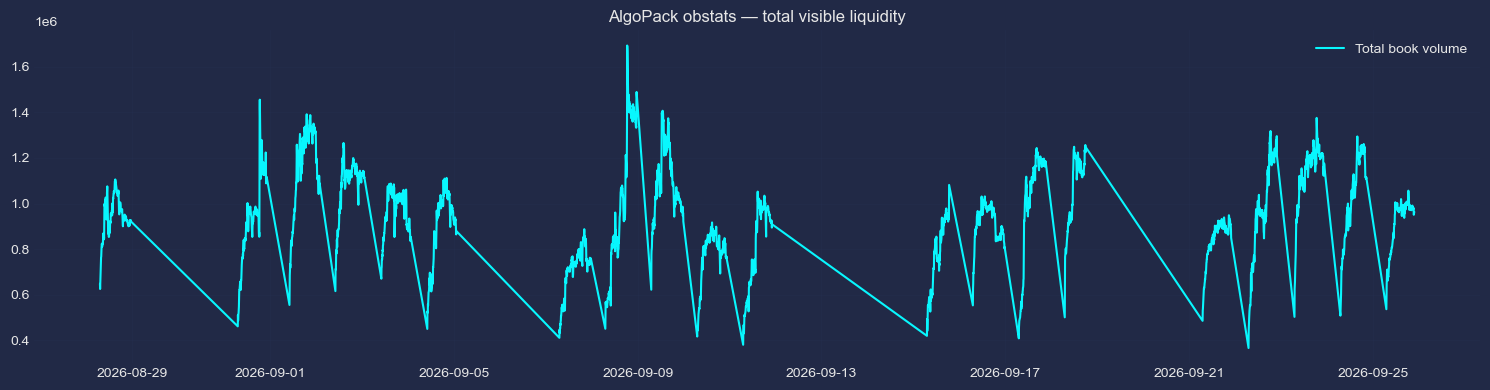

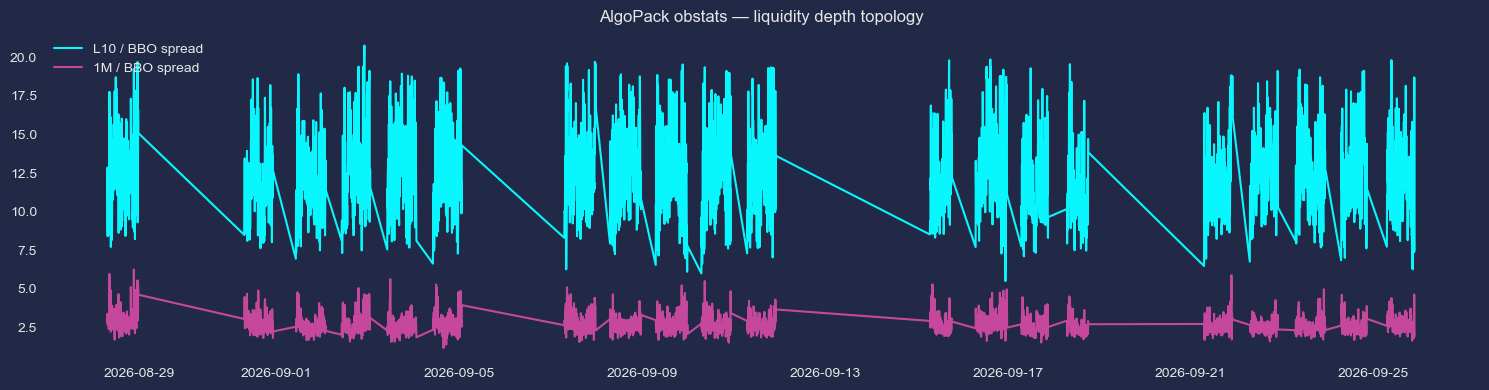

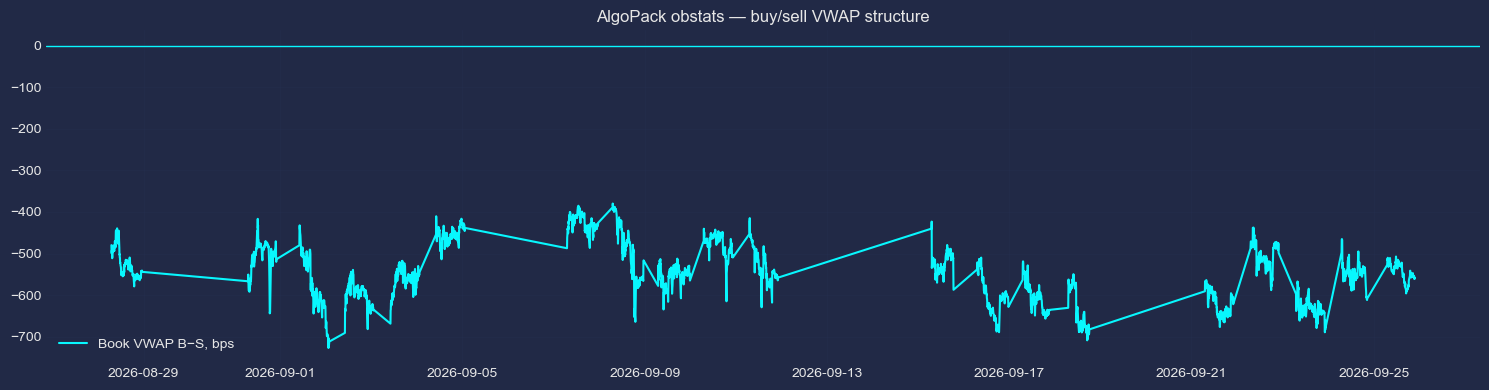

In [25]:

# ============================================================
# 📈 GROUP 12 VISUALIZATION
# ============================================================

if "obsf" in globals() and not obsf.empty:
    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(obsf["ts"], obsf["ob_total_volume"], label="Total book volume")
    ax.set_title("AlgoPack obstats — total visible liquidity")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(obsf["ts"], obsf["ob_lv10_to_bbo_spread_ratio"], label="L10 / BBO spread")
    ax.plot(obsf["ts"], obsf["ob_1mio_to_bbo_spread_ratio"], label="1M / BBO spread", alpha=0.75)
    ax.set_title("AlgoPack obstats — liquidity depth topology")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(obsf["ts"], obsf["ob_vwap_b_s_bps"], label="Book VWAP B−S, bps")
    ax.axhline(0, linewidth=1)
    ax.set_title("AlgoPack obstats — buy/sell VWAP structure")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


In [26]:
# Проверка наличия данных obstats
print("=== Диагностика obstats ===")
if "data" in globals():
    obstats_raw = data.get("obstats")
    if obstats_raw is not None:
        print(f"obstats shape: {obstats_raw.shape}")
        print(f"obstats columns: {obstats_raw.columns.tolist()}")
        print(f"obstats empty: {obstats_raw.empty}")
    else:
        print("❌ obstats не найден в data")
else:
    print("❌ Переменная data не найдена")

# Проверка feature_v2_groups
print("\n=== Проверка feature_v2_groups ===")
if "feature_v2_groups" in globals():
    print(f"Группы: {list(feature_v2_groups.keys())}")
    for name, cols in feature_v2_groups.items():
        print(f"  {name}: {len(cols)} candidates")
else:
    print("❌ feature_v2_groups не найден")

# Проверка feature_v2_frames
print("\n=== Проверка feature_v2_frames ===")
if "feature_v2_frames" in globals():
    print(f"Фреймы: {list(feature_v2_frames.keys())}")
    for name, frame in feature_v2_frames.items():
        print(f"  {name}: {frame.shape if frame is not None else 'None'}")
else:
    print("❌ feature_v2_frames не найден")

=== Диагностика obstats ===
obstats shape: (3540, 23)
obstats columns: ['secid', 'spread_bbo', 'spread_lv10', 'spread_1mio', 'levels_b', 'levels_s', 'vol_b', 'vol_s', 'val_b', 'val_s', 'imbalance_vol_bbo', 'imbalance_val_bbo', 'imbalance_vol', 'imbalance_val', 'vwap_b', 'vwap_s', 'vwap_b_1mio', 'vwap_s_1mio', 'SYSTIME', 'ts', 'ticker', 'super_kind', 'date']
obstats empty: False

=== Проверка feature_v2_groups ===
Группы: ['tradestats_pressure', 'orderstats_pressure', 'obstats_topology']
  tradestats_pressure: 94 candidates
  orderstats_pressure: 171 candidates
  obstats_topology: 132 candidates

=== Проверка feature_v2_frames ===
Фреймы: ['tradestats_pressure', 'orderstats_pressure', 'obstats_topology']
  tradestats_pressure: (3622, 95)
  orderstats_pressure: (3655, 172)
  obstats_topology: (3540, 133)



## 🆕 GROUP 13 — `orderbook.parquet`: настоящий 10×10 snapshot

Диагностика наконец показала реальную структуру:

```text
BUYSELL | PRICE | QUANTITY | SEQNUM | UPDATETIME
```

и ровно 20 строк:

- 10 bid;
- 10 ask.

То есть предыдущая логика с `bid_price_1`, `ask_price_1`, `bid_volume_1` и т.п. действительно была несовместима с реальным AlgoPack schema.

Но есть важное ограничение:

> этот файл содержит один snapshot на день, а не поток изменений стакана.

Поэтому мы можем корректно вычислить:

- OBI L1/L3/L5/L10;
- weighted OBI;
- microprice;
- book slope;
- depth concentration;
- distance to L10;
- price gaps;
- liquidity concentration.

Но **нельзя** считать это историческим intraday orderbook feature feed.

Эта группа остаётся отдельным snapshot-исследованием и не загрязняет causal historical matrix.


✅ Raw orderbook snapshot features: 28


,value
snapshot_bid1,23.695000
snapshot_ask1,20.645000
snapshot_mid,22.170000
snapshot_spread,-3.050000
snapshot_spread_bps,-1375.732972
snapshot_obi_l1,0.920725
snapshot_bid_depth_l1,1696.000000
snapshot_ask_depth_l1,70.000000
snapshot_depth_ratio_l1,24.228571
snapshot_obi_l3,0.826000


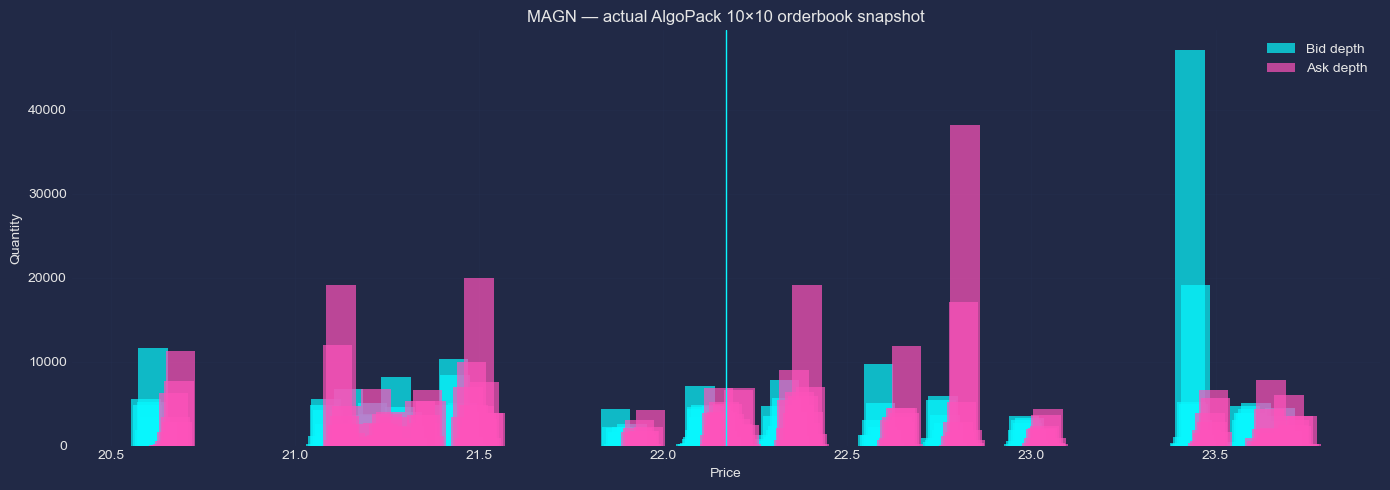

In [27]:

# ============================================================
# 🆕 GROUP 13 — RAW ORDERBOOK SNAPSHOT
# ============================================================

def build_orderbook_snapshot_features(ob):
    if ob is None or ob.empty:
        return pd.DataFrame()

    x = ob.copy()
    x["BUYSELL"] = x["BUYSELL"].astype(str).str.upper()
    x["PRICE"] = pd.to_numeric(x["PRICE"], errors="coerce")
    x["QUANTITY"] = pd.to_numeric(x["QUANTITY"], errors="coerce")
    x = x.dropna(subset=["PRICE","QUANTITY"])

    bids = x[x["BUYSELL"] == "B"].sort_values("PRICE", ascending=False).head(10)
    asks = x[x["BUYSELL"] == "S"].sort_values("PRICE", ascending=True).head(10)

    if len(bids) == 0 or len(asks) == 0:
        return pd.DataFrame()

    bid_p = bids["PRICE"].to_numpy()
    bid_q = bids["QUANTITY"].to_numpy()
    ask_p = asks["PRICE"].to_numpy()
    ask_q = asks["QUANTITY"].to_numpy()

    n = min(len(bid_p), len(ask_p), 10)

    bid_p, bid_q = bid_p[:n], bid_q[:n]
    ask_p, ask_q = ask_p[:n], ask_q[:n]

    bid1, ask1 = bid_p[0], ask_p[0]
    mid = (bid1 + ask1) / 2

    rows = {
        "snapshot_bid1": bid1,
        "snapshot_ask1": ask1,
        "snapshot_mid": mid,
        "snapshot_spread": ask1 - bid1,
        "snapshot_spread_bps": (ask1 - bid1) / (mid + 1e-12) * 1e4,
    }

    for L in [1, 3, 5, 10]:
        L = min(L, n)
        bq = bid_q[:L].sum()
        aq = ask_q[:L].sum()

        rows[f"snapshot_obi_l{L}"] = (bq - aq) / (bq + aq + 1e-12)
        rows[f"snapshot_bid_depth_l{L}"] = bq
        rows[f"snapshot_ask_depth_l{L}"] = aq
        rows[f"snapshot_depth_ratio_l{L}"] = bq / (aq + 1e-12)

    # Weighted imbalance: closer levels get more weight.
    weights = 1 / np.arange(1, n + 1)
    wb = np.sum(bid_q * weights)
    wa = np.sum(ask_q * weights)
    rows["snapshot_weighted_obi"] = (wb - wa) / (wb + wa + 1e-12)

    # Microprice using best queues.
    rows["snapshot_microprice"] = (
        ask1 * bid_q[0] + bid1 * ask_q[0]
    ) / (bid_q[0] + ask_q[0] + 1e-12)

    rows["snapshot_microprice_edge_bps"] = (
        rows["snapshot_microprice"] - mid
    ) / (mid + 1e-12) * 1e4

    # Book slope / price distance.
    rows["snapshot_bid_l10_distance_bps"] = (
        (bid1 - bid_p[-1]) / (mid + 1e-12) * 1e4
    )
    rows["snapshot_ask_l10_distance_bps"] = (
        (ask_p[-1] - ask1) / (mid + 1e-12) * 1e4
    )

    # Liquidity concentration.
    rows["snapshot_bid_l1_share_l10"] = bid_q[0] / (bid_q.sum() + 1e-12)
    rows["snapshot_ask_l1_share_l10"] = ask_q[0] / (ask_q.sum() + 1e-12)

    return pd.DataFrame([rows])


# Используем последний доступный snapshot, но только как snapshot.
ob_raw = data.get("orderbook")

if isinstance(ob_raw, pd.DataFrame) and not ob_raw.empty:
    snapshot_features = build_orderbook_snapshot_features(ob_raw)

    feature_v2_groups["orderbook_snapshot"] = snapshot_features.columns.tolist()

    print("✅ Raw orderbook snapshot features:", len(snapshot_features.columns))
    display(snapshot_features.T.rename(columns={0: "value"}))

    # Визуальная форма стакана.
    x = ob_raw.copy()
    x["BUYSELL"] = x["BUYSELL"].astype(str).str.upper()

    bids = x[x["BUYSELL"] == "B"].sort_values("PRICE", ascending=False)
    asks = x[x["BUYSELL"] == "S"].sort_values("PRICE", ascending=True)

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.bar(bids["PRICE"], bids["QUANTITY"], width=0.08, alpha=0.7, label="Bid depth")
    ax.bar(asks["PRICE"], asks["QUANTITY"], width=0.08, alpha=0.7, label="Ask depth")
    ax.axvline(snapshot_features["snapshot_mid"].iloc[0], linewidth=1)
    ax.set_title(f"{FEATURE_LAB_TICKER} — actual AlgoPack 10×10 orderbook snapshot")
    ax.set_xlabel("Price")
    ax.set_ylabel("Quantity")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
else:
    print("❌ orderbook snapshot unavailable")



## 🆕 GROUP 14 — Cross-source confirmation / divergence

Теперь у нас есть три независимых взгляда на один и тот же рынок:

```text
TRADESTATS  → что реально торговалось
ORDERSTATS  → что выставляли / снимали
OBSTATS     → какая ликвидность была доступна
```

Самые интересные признаки часто возникают **не внутри одного источника, а при их противоречии**.

Например:

### Absorption-like state

Продажи по trades сильные, но:
- book imbalance не становится резко bearish;
- bid liquidity остаётся высокой;
- cancellation bid не ускоряется.

### Exhaustion-like state

Сильный buy flow, но:
- price change слабый;
- sell-side cancellation растёт;
- book VWAP начинает расходиться.

### Liquidity vacuum

- spread расширяется;
- total book liquidity падает;
- cancellation / placement ratio растёт.

Это пока только feature candidates — не готовые торговые сигналы.


In [28]:

# ============================================================
# 🆕 GROUP 14 — CROSS-SOURCE DIVERGENCE
# ============================================================

if not feature_v2_frames:
    print("❌ No v2 frames")
else:
    cross = None

    for name in ["tradestats_pressure", "orderstats_pressure", "obstats_topology"]:
        frame = feature_v2_frames.get(name)
        if frame is None or frame.empty:
            continue

        if cross is None:
            cross = frame.copy()
        else:
            cross = pd.merge_asof(
                cross.sort_values("ts"),
                frame.sort_values("ts"),
                on="ts",
                direction="backward",
                suffixes=("", f"_{name}")
            )

    if cross is not None:

        # Helper columns.
        # Trade flow vs order placement.
        if "ts_volume_imbalance" in cross and "os_put_volume_imb" in cross:
            cross["x_trade_vs_placement_imb"] = (
                cross["ts_volume_imbalance"] -
                cross["os_put_volume_imb"]
            )

        # Trade flow vs cancellation.
        if "ts_volume_imbalance" in cross and "os_cancel_volume_imb" in cross:
            cross["x_trade_vs_cancel_imb"] = (
                cross["ts_volume_imbalance"] -
                cross["os_cancel_volume_imb"]
            )

        # Net order-flow vs trade-flow.
        if "ts_volume_imbalance" in cross and "os_net_volume_imb" in cross:
            cross["x_trade_vs_net_order_imb"] = (
                cross["ts_volume_imbalance"] -
                cross["os_net_volume_imb"]
            )

        # Book liquidity vs trade pressure.
        if "ts_volume_imbalance" in cross and "ob_vol_imb_bbo_vs_deep" in cross:
            cross["x_trade_vs_book_depth_divergence"] = (
                cross["ts_volume_imbalance"] -
                cross["ob_vol_imb_bbo_vs_deep"]
            )

        # Flow intensity against cancellation intensity.
        if "ts_value_per_trade" in cross and "os_cancel_to_put_value" in cross:
            cross["x_trade_size_x_cancel_pressure"] = (
                np.log1p(cross["ts_value_per_trade"].clip(lower=0)) *
                np.log1p(cross["os_cancel_to_put_value"].clip(lower=0))
            )

        xcols = [
            c for c in cross.columns
            if c.startswith("x_")
        ]

        feature_v2_groups["cross_source_divergence"] = xcols
        feature_v2_frames["cross_source_divergence"] = cross[["ts"] + xcols]

        print(f"✅ cross-source divergence: {len(xcols)} candidates")
        display(cross[["ts"] + xcols].tail(10))


✅ cross-source divergence: 5 candidates


,ts,x_trade_vs_placement_imb,x_trade_vs_cancel_imb,x_trade_vs_net_order_imb,x_trade_vs_book_depth_divergence,x_trade_size_x_cancel_pressure
3612,2026-09-25 20:55:00+03:00,-0.695898,-0.691222,-0.841552,-0.456931,6.958871
3613,2026-09-25 21:00:00+03:00,0.336453,0.351519,0.505099,1.282973,6.659414
3614,2026-09-25 21:05:00+03:00,-0.436041,-0.449522,0.075654,-0.143917,6.789762
3615,2026-09-25 21:10:00+03:00,0.092099,0.093413,0.523593,0.563333,4.419801
3616,2026-09-25 21:15:00+03:00,-1.272227,-1.310384,-0.778062,-1.781581,6.920547
3617,2026-09-25 21:20:00+03:00,-0.986702,-0.803937,-1.481513,-0.669061,6.457730
3618,2026-09-25 21:25:00+03:00,-1.289273,-1.286548,-0.859681,-1.890159,6.034316
3619,2026-09-25 21:30:00+03:00,-1.056495,-1.002873,-1.460933,-1.343974,4.738002
3620,2026-09-25 21:35:00+03:00,0.384135,0.338329,0.809010,1.553658,7.077887
3621,2026-09-25 21:40:00+03:00,-0.345027,-0.373867,0.226359,0.074146,6.831319



## 🔗 GROUP 15 — Strict causal merge into Dollar Bars

Теперь все новые supercandles features присоединяются к `dollar_bars` только через:

```python
merge_asof(..., direction="backward")
```

То есть:

> feature timestamp ≤ bar timestamp

Никакого forward-fill из будущего.

Кроме того, для контроля качества выводим:
- количество dollar bars;
- покрытие каждым источником;
- количество новых numeric columns;
- количество строк с хотя бы одним новым feature;
- максимальный age последнего доступного supercandle относительно bar.

Это будет нашей контрольной точкой перед будущим feature selection / model testing.


In [29]:
# ============================================================
# 🔗 GROUP 15 — STRICT CAUSAL FEATURE MATRIX V2
# ============================================================

def causal_merge(base, extra):
    if base is None or not isinstance(base, pd.DataFrame) or base.empty:
        return pd.DataFrame()

    if extra is None or extra.empty:
        return base.copy()

    b = base.copy()

    # Normalize timestamp.
    if "ts" not in b.columns:
        if "timestamp" in b.columns:
            b["ts"] = pd.to_datetime(b["timestamp"], errors="coerce")
        else:
            return b

    b["ts"] = pd.to_datetime(b["ts"], errors="coerce")

    e = extra.copy()
    e["ts"] = pd.to_datetime(e["ts"], errors="coerce")

    e = e.dropna(subset=["ts"]).sort_values("ts")
    b = b.dropna(subset=["ts"]).sort_values("ts")

    # Only numeric candidate columns.
    cols = []
    for c in e.columns:
        if c == "ts":
            continue
        if pd.api.types.is_numeric_dtype(e[c]):
            cols.append(c)

    if not cols:
        return b

    e = e[["ts"] + cols].copy()

    # Duplicate column protection.
    collisions = [c for c in cols if c in b.columns]
    e = e.drop(columns=collisions, errors="ignore")

    return pd.merge_asof(
        b,
        e,
        on="ts",
        direction="backward"
    )


# Build combined V2 source frame.
source_frames = []

for name, frame in feature_v2_frames.items():
    if frame is None or frame.empty:
        continue

    f = frame.copy()

    # Cross-source frame is already derived.
    source_frames.append((name, f))

# Base.
if "dollar_bars" in globals():
    v2_matrix = dollar_bars.copy()

    # ========================================================================
    # ИСПРАВЛЕНИЕ: если "ts" нет в колонках, но есть DatetimeIndex —
    # сбрасываем индекс и переименовываем в "ts"
    # ========================================================================
    if "ts" not in v2_matrix.columns:
        if isinstance(v2_matrix.index, pd.DatetimeIndex):
            idx_name = v2_matrix.index.name
            v2_matrix = v2_matrix.reset_index()
            # Переименовываем колонку индекса в "ts"
            if idx_name and idx_name != "ts":
                v2_matrix = v2_matrix.rename(columns={idx_name: "ts"})
            elif "index" in v2_matrix.columns and "ts" not in v2_matrix.columns:
                v2_matrix = v2_matrix.rename(columns={"index": "ts"})
    # ========================================================================

    # Normalize common uppercase schema.
    rename_map = {}
    for a, b in [
        ("OPEN", "open"),
        ("HIGH", "high"),
        ("LOW", "low"),
        ("CLOSE", "close"),
        ("VOLUME", "volume"),
        ("VALUE", "value"),
    ]:
        if a in v2_matrix.columns and b not in v2_matrix.columns:
            rename_map[a] = b

    v2_matrix = v2_matrix.rename(columns=rename_map)

    if "ts" not in v2_matrix.columns:
        raise ValueError("dollar_bars must contain ts")

    v2_matrix["ts"] = pd.to_datetime(v2_matrix["ts"], errors="coerce")

    before_cols = set(v2_matrix.columns)

    # Merge source-by-source.
    for name, frame in source_frames:
        v2_matrix = causal_merge(v2_matrix, frame)

    # Feature columns introduced by V2.
    new_cols = [
        c for c in v2_matrix.columns
        if c not in before_cols and c != "ts"
        and pd.api.types.is_numeric_dtype(v2_matrix[c])
    ]

    v2_new_cols = new_cols

    print("=" * 100)
    print("JERICHON FEATURE LAB v2 — CAUSAL MATRIX")
    print("=" * 100)
    print("Dollar bars:", len(v2_matrix))
    print("New numeric features:", len(v2_new_cols))
    print("Final numeric columns:", len(v2_matrix.select_dtypes(include=np.number).columns))

    if len(v2_new_cols):
        coverage = (
            v2_matrix[v2_new_cols]
            .notna()
            .mean()
            .sort_values(ascending=False)
            .mul(100)
        )

        print("\nCoverage of new features, %:")
        display(coverage.to_frame("coverage_pct").head(100))

    # Leakage sanity check:
    # all merge_asof joins are backward, so each source timestamp <= bar timestamp.
    print("\n✅ All V2 source joins use direction='backward'.")
    print("⚠️ Raw orderbook snapshot is intentionally NOT merged into historical intraday matrix.")

else:
    print("❌ dollar_bars not found. Run the original research pipeline first.")

JERICHON FEATURE LAB v2 — CAUSAL MATRIX
Dollar bars: 2801
New numeric features: 402
Final numeric columns: 409

Coverage of new features, %:


,coverage_pct
ts_trade_imbalance,100.0
os_cancel_to_put_volume_chg,100.0
os_cancel_to_put_volume_ma12,100.0
os_cancel_to_put_volume_z6,100.0
os_cancel_to_put_volume_ma6,100.0
...,...
ob_lv10_to_bbo_spread_ratio,100.0
ob_1mio_to_bbo_spread_ratio,100.0
ob_vwap_b_s_bps,100.0
ob_vwap_1mio_b_s_bps,100.0



✅ All V2 source joins use direction='backward'.
⚠️ Raw orderbook snapshot is intentionally NOT merged into historical intraday matrix.



# 📊 FINAL V2 INVENTORY — what we actually gained

Здесь считаем не «сколько колонок придумали», а сколько **реально новых numeric candidates** дошло до causal matrix.

Отдельно показываем:

1. кандидаты по источникам;
2. реально новые после удаления collisions;
3. coverage;
4. источники, которые потенциально стоит оставить для дальнейшего исследования.

Следующий этап после этого блока — уже не добавление случайных признаков, а проверка **predictive information / redundancy / stability through time**.


In [30]:
# ============================================================
# 📊 FINAL V2 INVENTORY
# ============================================================

print("=" * 110)
print("JERICHON FEATURE LAB v2 — FINAL INVENTORY")
print("=" * 110)

rows = []

for group, cols in feature_v2_groups.items():
    rows.append({
        "group": group,
        "candidate_features": len(cols),
    })

inventory = pd.DataFrame(rows).sort_values(
    "candidate_features", ascending=False
)

display(inventory)

print("\nCandidate features by source:")
print(
    inventory.to_string(index=False)
)

if "v2_new_cols" in globals():
    print("\n" + "-" * 110)
    print("REAL NEW FEATURES IN CAUSAL MATRIX:", len(v2_new_cols))
    print("-" * 110)

    for i, c in enumerate(v2_new_cols, 1):
        print(f"{i:>3}. {c}")

    # Feature matrix compact preview.
    preview_cols = ["ts"] + v2_new_cols[:30]
    print("\nPreview:")
    display(v2_matrix[preview_cols].tail(10))


JERICHON FEATURE LAB v2 — FINAL INVENTORY


,group,candidate_features
1,orderstats_pressure,171
2,obstats_topology,132
0,tradestats_pressure,94
3,orderbook_snapshot,28
4,cross_source_divergence,5



Candidate features by source:
                  group  candidate_features
    orderstats_pressure                 171
       obstats_topology                 132
    tradestats_pressure                  94
     orderbook_snapshot                  28
cross_source_divergence                   5

--------------------------------------------------------------------------------------------------------------
REAL NEW FEATURES IN CAUSAL MATRIX: 402
--------------------------------------------------------------------------------------------------------------
  1. ts_trade_imbalance
  2. ts_volume_imbalance
  3. ts_value_imbalance
  4. ts_buy_trade_share
  5. ts_buy_volume_share
  6. ts_buy_value_share
  7. ts_vwap_b_s_diff
  8. ts_vwap_b_s_bps
  9. ts_buy_vwap_displacement
 10. ts_sell_vwap_displacement
 11. ts_value_per_trade
 12. ts_volume_per_trade
 13. ts_flow_x_return
 14. ts_flow_x_volatility
 15. ts_trade_imbalance_chg
 16. ts_trade_imbalance_ret
 17. ts_trade_imbalance_ma3
 18. ts_tra

,ts,ts_trade_imbalance,ts_volume_imbalance,ts_value_imbalance,ts_buy_trade_share,ts_buy_volume_share,ts_buy_value_share,ts_vwap_b_s_diff,ts_vwap_b_s_bps,ts_buy_vwap_displacement,...,ts_trade_imbalance_ma12,ts_trade_imbalance_z12,ts_trade_imbalance_ma24,ts_trade_imbalance_z24,ts_volume_imbalance_chg,ts_volume_imbalance_ret,ts_volume_imbalance_ma3,ts_volume_imbalance_z3,ts_volume_imbalance_ma6,ts_volume_imbalance_z6
2791,2026-09-25 18:22:58+03:00,0.612167,0.584771,0.584724,0.806084,0.792385,0.792362,-0.003,-1.420488,0.000000,...,0.294792,1.208705,0.145207,1.307191,-0.215653,-0.269424,0.715422,-1.137626,0.261276,0.519781
2792,2026-09-25 18:26:15+03:00,0.590392,0.711343,0.711771,0.795196,0.855672,0.855885,0.036,16.973126,0.000236,...,0.329285,0.957788,0.189310,1.168371,0.126572,0.216448,0.698846,0.115322,0.421148,0.493823
2793,2026-09-25 18:37:14+03:00,-0.458647,-0.858731,-0.858713,0.270677,0.070635,0.070643,0.003,1.417535,0.000095,...,0.223462,-1.806168,0.161892,-1.691843,-0.241909,0.392187,-0.254736,-0.714493,0.230343,-1.438126
2794,2026-09-25 18:49:14+03:00,-0.722628,-0.954409,-0.954374,0.138686,0.022796,0.022813,0.017,8.037255,0.000804,...,0.132234,-1.871858,0.130948,-2.081104,-1.182792,-5.178986,-0.528252,-0.648631,-0.150911,-1.075206
2795,2026-09-25 19:18:45+03:00,-0.173913,-0.417896,-0.417631,0.413043,0.291052,0.291184,0.013,6.146427,0.000426,...,0.123942,-0.547257,0.203125,-0.893789,0.149124,-0.262997,-0.606275,0.893783,0.004838,-0.567000
2796,2026-09-25 19:34:06+03:00,-0.191176,-0.350003,-0.349503,0.404412,0.324999,0.325248,0.024,11.345372,0.000757,...,-0.015676,-0.330697,0.140860,-0.729397,-0.557292,-2.688474,0.204487,-1.002524,-0.200894,-0.256728
2797,2026-09-25 20:09:45+03:00,0.571429,0.857463,0.857552,0.785714,0.928731,0.928776,0.014,6.614069,0.000047,...,0.029028,1.269168,0.123341,0.895089,1.615675,-2.130900,-0.245549,1.153747,0.114167,0.894636
2798,2026-09-25 20:40:17+03:00,0.612903,0.735052,0.735048,0.806452,0.867526,0.867524,0.000,0.000000,0.000000,...,0.089785,1.073956,0.082680,1.057663,0.847900,-7.513636,0.330138,0.952224,0.048078,0.888464
2799,2026-09-25 21:30:47+03:00,0.777778,-0.403974,-0.403886,0.888889,0.298013,0.298057,0.005,2.358212,0.000189,...,0.135761,1.401570,0.127450,1.408429,0.556186,-0.579264,-0.644398,0.841693,-0.400893,-0.005294
2800,2026-09-25 21:42:45+03:00,-0.555556,0.024146,0.024491,0.222222,0.512073,0.512245,0.015,7.066305,0.000330,...,0.108997,-1.276546,0.099391,-1.328126,-0.939512,-0.974944,0.194610,-0.243670,-0.321162,0.471410


In [31]:
print("=== Проверка наличия групп ===")
for name in ["tradestats_pressure", "orderstats_pressure", 
             "obstats_topology", "orderbook_snapshot", 
             "cross_source_divergence"]:
    exists = name in feature_v2_groups
    n = len(feature_v2_groups.get(name, []))
    print(f"  {name:30s} → {'✅' if exists else '❌'} ({n} candidates)")

print(f"\nv2_new_cols: {len(v2_new_cols) if 'v2_new_cols' in globals() else 'не определён'}")
print(f"v2_matrix shape: {v2_matrix.shape if 'v2_matrix' in globals() else 'не определён'}")

=== Проверка наличия групп ===
  tradestats_pressure            → ✅ (94 candidates)
  orderstats_pressure            → ✅ (171 candidates)
  obstats_topology               → ✅ (132 candidates)
  orderbook_snapshot             → ✅ (28 candidates)
  cross_source_divergence        → ✅ (5 candidates)

v2_new_cols: 402
v2_matrix shape: (2801, 412)


In [32]:
# =============================================================================
# Cell 1: Подготовка данных — используем ВСЕ признаки (старые + новые)
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import TimeSeriesSplit
import warnings
warnings.filterwarnings('ignore')

print("=== Cell 1: Подготовка данных (ВСЕ признаки) ===")

# Проверяем что v2_matrix существует
if "v2_matrix" not in globals():
    raise ValueError("v2_matrix не найден. Сначала выполни ячейку GROUP 15 — CAUSAL MATRIX")

print(f"v2_matrix shape: {v2_matrix.shape}")
print(f"Новых признаков (v2_new_cols): {len(v2_new_cols) if 'v2_new_cols' in globals() else 0}")

# =============================================================================
# ИСПРАВЛЕНИЕ: Добавляем старые признаки из bars_featured в v2_matrix
# =============================================================================
if "bars_featured" in globals():
    # Берём только числовые колонки из bars_featured
    old_numeric = bars_featured.select_dtypes(include=[np.number]).copy()
    
    # Убираем 'ts' если есть (он уже есть в v2_matrix)
    if "ts" in old_numeric.columns:
        old_numeric = old_numeric.drop(columns=["ts"])
    
    # Если индекс — DatetimeIndex, сбрасываем в колонку 'ts'
    if isinstance(old_numeric.index, pd.DatetimeIndex):
        idx_name = old_numeric.index.name
        old_numeric = old_numeric.reset_index()
        if idx_name and idx_name != "ts":
            old_numeric = old_numeric.rename(columns={idx_name: "ts"})
        elif "index" in old_numeric.columns and "ts" not in old_numeric.columns:
            old_numeric = old_numeric.rename(columns={"index": "ts"})
    
    # Удаляем колонки, которые уже есть в v2_matrix (избегаем дубликатов)
    cols_to_add = [c for c in old_numeric.columns if c not in v2_matrix.columns and c != "ts"]
    old_numeric_subset = old_numeric[["ts"] + cols_to_add].copy()
    
    print(f"\n📌 Добавляем {len(cols_to_add)} старых признаков из bars_featured в v2_matrix")
    print(f"   Колонки для добавления: {cols_to_add[:10]}{'...' if len(cols_to_add) > 10 else ''}")
    
    # Causal merge: старые признаки → v2_matrix
    old_numeric_subset["ts"] = pd.to_datetime(old_numeric_subset["ts"], errors="coerce")
    v2_matrix_full = v2_matrix.copy()
    v2_matrix_full["ts"] = pd.to_datetime(v2_matrix_full["ts"], errors="coerce")
    
    v2_matrix_full = pd.merge_asof(
        v2_matrix_full.sort_values("ts"),
        old_numeric_subset.sort_values("ts"),
        on="ts",
        direction="backward"
    )
    
    print(f"   v2_matrix_full shape: {v2_matrix_full.shape}")
else:
    print("⚠️ bars_featured не найден, используем только новые признаки")
    v2_matrix_full = v2_matrix.copy()
    cols_to_add = []

# =============================================================================
# Собираем финальный список признаков
# =============================================================================

# Все числовые колонки из полной матрицы
all_numeric_cols = [
    c for c in v2_matrix_full.columns 
    if c != "ts" and pd.api.types.is_numeric_dtype(v2_matrix_full[c])
]

print(f"\n📊 ИТОГО числовых признаков: {len(all_numeric_cols)}")
print(f"   Из них старых (из bars_featured): {len(cols_to_add)}")
print(f"   Из них новых (из Feature Lab v2): {len(v2_new_cols)}")

# =============================================================================
# Создаем X и y
# =============================================================================

if "labeled" not in globals():
    raise ValueError("labeled не найден. Сначала выполни ячейку TRIPLE BARRIER")

# Объединяем v2_matrix_full с labeled
v2_with_labels = v2_matrix_full.merge(
    labeled[['label']], 
    left_on='ts', 
    right_index=True, 
    how='inner'
)

print(f"\nПосле merge с labeled: {len(v2_with_labels)} строк")

# Фильтруем только бинарные события (UP=1, DOWN=-1, убираем TIME=0)
mask_bin = v2_with_labels['label'].isin([1, -1])
X_all = v2_with_labels.loc[mask_bin, all_numeric_cols].copy()
y_all = v2_with_labels.loc[mask_bin, 'label'].map({1: 1, -1: 0}).copy()

print(f"Бинарных событий: {len(X_all)} (UP: {y_all.sum()}, DOWN: {len(y_all) - y_all.sum()})")

# =============================================================================
# Train/Test split
# =============================================================================
TRAIN_RATIO = 0.75
split_idx = int(len(X_all) * TRAIN_RATIO)

X_train = X_all.iloc[:split_idx].copy()
X_test = X_all.iloc[split_idx:].copy()
y_train = y_all.iloc[:split_idx].copy()
y_test = y_all.iloc[split_idx:].copy()

# Заполняем пропуски (могут появиться из-за merge_asof)
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

print(f"\nTrain: {len(X_train)}, Test: {len(X_test)}")
print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print(f"\n✅ Готово! Теперь у нас {X_train.shape[1]} признаков для мясорубки")

# Сохраняем список всех признаков для дальнейшего использования
ALL_FEATURES = all_numeric_cols

=== Cell 1: Подготовка данных (ВСЕ признаки) ===
v2_matrix shape: (2801, 412)
Новых признаков (v2_new_cols): 402

📌 Добавляем 66 старых признаков из bars_featured в v2_matrix
   Колонки для добавления: ['rsi', 'macd', 'macd_signal', 'macd_hist', 'bb_upper', 'bb_lower', 'bb_width', 'bb_position', 'atr', 'obv']...
   v2_matrix_full shape: (2801, 478)

📊 ИТОГО числовых признаков: 475
   Из них старых (из bars_featured): 66
   Из них новых (из Feature Lab v2): 402

После merge с labeled: 1266 строк
Бинарных событий: 1266 (UP: 606, DOWN: 660)

Train: 949, Test: 317
Train shape: (949, 475)
Test shape: (317, 475)

✅ Готово! Теперь у нас 475 признаков для мясорубки


🚀 Запуск бэктеста на 475 признаках...
Test period: 2026-09-17 17:56:54+03:00 → 2026-09-25 20:09:45+03:00
Test events: 317

▶ XGBoost
   Return: -7.00% | Trades: 297 | Sharpe: -2.28 | MaxDD: -9.10%
▶ Random Forest
   Return: +4.76% | Trades: 300 | Sharpe: 1.76 | MaxDD: -1.94%
▶ LightGBM
   Return: -17.50% | Trades: 297 | Sharpe: -5.53 | MaxDD: -17.75%
▶ CatBoost
   Return: -1.15% | Trades: 300 | Sharpe: -0.38 | MaxDD: -6.20%



,Model,Return_%,MaxDD_%,Sharpe,ProfitFactor,WinRate_%,Trades,TP,SL,Vertical,Forced23,Reversals,Trades/day
0,XGBoost,-7.00%,-9.10%,-2.28,0.71,74.7%,297,79,213,0,0,4,36.70
1,Random Forest,+4.76%,-1.94%,1.76,1.31,85.0%,300,51,245,0,0,3,37.07
2,LightGBM,-17.50%,-17.75%,-5.53,0.45,65.7%,297,105,185,0,0,6,36.70
3,CatBoost,-1.15%,-6.20%,-0.38,0.94,80.0%,300,59,233,0,0,7,37.07


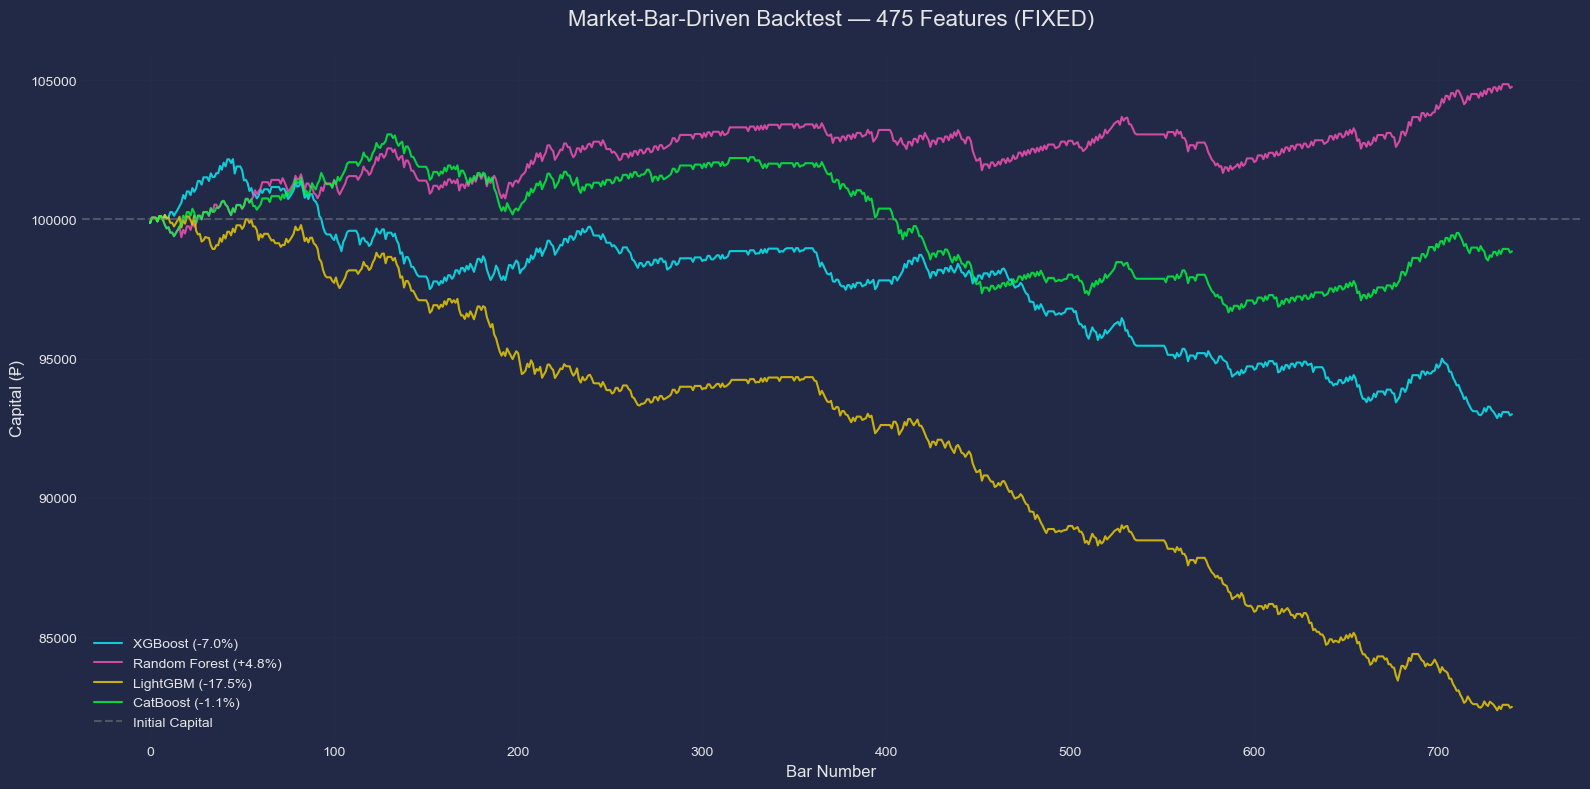

In [40]:
# =============================================================================
# MARKET-BAR-DRIVEN BACKTEST (ИСПРАВЛЕННАЯ ПРИВЯЗКА СИГНАЛОВ)
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INITIAL_CAPITAL = 100_000
COMMISSION = 0.0006
SLIPPAGE = 0.0001
ENTRY_CUTOFF_HOUR = 21
FORCED_CLOSE_HOUR = 23

# ИСПРАВЛЕНИЕ: Привязываем предсказания к Timestamp из labeled_test, 
# а не к сломанному целочисленному индексу X_test
def get_signals_dict(model, X_test, labeled_test):
    preds = model.predict(X_test)
    model_classes = model.classes_ if hasattr(model, 'classes_') else np.unique(y_train)
    signals = np.where(preds == 1, 1, -1) if set(model_classes) == {0, 1} else preds
    
    # Берем минимальную длину на случай небольших несовпадений
    valid_len = min(len(signals), len(labeled_test))
    
    # Создаем словарь: {Timestamp: signal}
    return {labeled_test.index[i]: int(signals[i]) for i in range(valid_len)}

def run_bar_driven_backtest(model, X_train, y_train, X_test, labeled_test, dollar_bars,
                            initial_capital=INITIAL_CAPITAL, commission=COMMISSION, slippage=SLIPPAGE):
    model.fit(X_train, y_train)
    signals_dict = get_signals_dict(model, X_test, labeled_test)
    
    test_start = labeled_test.index.min()
    test_end = labeled_test.index.max()
    
    test_bars = dollar_bars.loc[test_start:test_end].copy()
    
    capital = float(initial_capital)
    equity_curve = []
    equity_times = []
    trades = []
    position = None
    
    diag = {'ml_events': len(signals_dict), 'long_signals': 0, 'short_signals': 0, 
            'signal_changes': 0, 'holds': 0, 'entries': 0, 'exits': 0, 'reversals': 0,
            'tp_exits': 0, 'sl_exits': 0, 'vertical_exits': 0, 'forced_exits': 0}
    
    prev_signal = 0
    
    def close_pos(pos, close_price, close_time, reason):
        nonlocal capital
        mult = pos['lots']
        gross = (close_price - pos['entry_price']) * mult if pos['side'] == 'long' else (pos['entry_price'] - close_price) * mult
        fees = (pos['entry_price'] * mult + close_price * mult) * commission
        pnl = gross - fees
        pnl_pct = (pnl / (pos['entry_price'] * mult) * 100) if pos['entry_price'] > 0 else 0
        
        capital += pnl
        trades.append({'entry_time': pos['entry_time'], 'exit_time': close_time, 'side': pos['side'],
                       'entry': pos['entry_price'], 'exit': close_price, 'pnl': pnl, 'pnl_pct': pnl_pct, 'exit_reason': reason})
        diag['exits'] += 1
        if reason == 'take_profit': diag['tp_exits'] += 1
        elif reason == 'stop_loss': diag['sl_exits'] += 1
        elif reason == 'vertical_barrier': diag['vertical_exits'] += 1
        elif reason == 'forced_close_23': diag['forced_exits'] += 1

    # ГЛАВНЫЙ ЦИКЛ
    for bar_time, bar in test_bars.iterrows():
        curr_close = float(bar['CLOSE'])
        curr_high = float(bar['HIGH'])
        curr_low = float(bar['LOW'])
        
        # А) ПРОВЕРКА ВЫХОДОВ ПО ПОЗИЦИИ
        if position is not None:
            exited = False
            if position['side'] == 'long':
                if curr_low <= position['lower']:
                    close_pos(position, float(position['lower']), bar_time, 'stop_loss'); exited = True
                elif curr_high >= position['upper']:
                    close_pos(position, float(position['upper']), bar_time, 'take_profit'); exited = True
            else:
                if curr_high >= position['lower']:
                    close_pos(position, float(position['lower']), bar_time, 'stop_loss'); exited = True
                elif curr_low <= position['upper']:
                    close_pos(position, float(position['upper']), bar_time, 'take_profit'); exited = True
            
            if not exited and position['t1'] <= bar_time:
                close_pos(position, curr_close, bar_time, 'vertical_barrier'); exited = True
            
            if not exited and bar_time.hour >= FORCED_CLOSE_HOUR:
                close_pos(position, curr_close, bar_time, 'forced_close_23'); exited = True
            
            if exited:
                position = None

        # Б) ОБРАБОТКА ML СИГНАЛА
        # ТЕПЕРЬ ЭТО УСЛОВИЕ СРАБОТАЕТ, так как ключи в signals_dict - это Timestamps
        if bar_time in signals_dict:
            signal = signals_dict[bar_time]
            if signal == 1: diag['long_signals'] += 1
            elif signal == -1: diag['short_signals'] += 1
            
            if prev_signal != 0 and signal != prev_signal:
                diag['signal_changes'] += 1
            
            target_side = 'long' if signal == 1 else 'short'
            
            if position is None:
                if signal != 0 and bar_time.hour < ENTRY_CUTOFF_HOUR:
                    entry_price = curr_close * (1 + slippage if signal == 1 else 1 - slippage)
                    lots = capital / entry_price
                    entry_label = labeled_test.loc[bar_time]
                    position = {
                        'side': target_side, 'entry_price': entry_price, 'entry_time': bar_time, 'lots': lots,
                        'upper': float(entry_label['upper']), 'lower': float(entry_label['lower']),
                        't1': entry_label['t1'] if isinstance(entry_label['t1'], pd.Timestamp) else pd.to_datetime(entry_label['t1'])
                    }
                    diag['entries'] += 1
            else:
                if position['side'] == target_side:
                    diag['holds'] += 1
                else:
                    close_pos(position, curr_close, bar_time, 'reverse_signal')
                    diag['reversals'] += 1
                    
                    if bar_time.hour < ENTRY_CUTOFF_HOUR:
                        entry_price = curr_close * (1 + slippage if signal == 1 else 1 - slippage)
                        lots = capital / entry_price
                        entry_label = labeled_test.loc[bar_time]
                        position = {
                            'side': target_side, 'entry_price': entry_price, 'entry_time': bar_time, 'lots': lots,
                            'upper': float(entry_label['upper']), 'lower': float(entry_label['lower']),
                            't1': entry_label['t1'] if isinstance(entry_label['t1'], pd.Timestamp) else pd.to_datetime(entry_label['t1'])
                        }
                        diag['entries'] += 1
            
            prev_signal = signal

        # В) MARK-TO-MARKET EQUITY
        unrealized_pnl = 0
        if position is not None:
            mult = position['lots']
            unrealized_pnl = (curr_close - position['entry_price']) * mult if position['side'] == 'long' else (position['entry_price'] - curr_close) * mult
            fees = (position['entry_price'] * mult + curr_close * mult) * commission
            unrealized_pnl -= fees
            
        equity_curve.append(capital + unrealized_pnl)
        equity_times.append(bar_time)

    # Финальное закрытие
    if position is not None:
        last_time = test_bars.index[-1]
        close_pos(position, float(test_bars.loc[last_time, 'CLOSE']), last_time, 'final_close')

    # Метрики
    df_trades = pd.DataFrame(trades)
    equity_array = np.array(equity_curve)
    total_return = (capital - initial_capital) / initial_capital * 100
    max_drawdown = ((equity_array - np.maximum.accumulate(equity_array)) / np.maximum.accumulate(equity_array)).min() * 100 if len(equity_array) > 1 else 0
    
    if not df_trades.empty:
        returns = df_trades['pnl_pct']
        sharpe = (returns.mean() / returns.std()) * np.sqrt(len(returns)) if returns.std() > 0 else 0
        win_rate = (df_trades['pnl'] > 0).mean() * 100
        profit_factor = abs(df_trades[df_trades['pnl'] > 0]['pnl'].sum() / df_trades[df_trades['pnl'] < 0]['pnl'].sum()) if (df_trades['pnl'] < 0).any() else np.inf
    else:
        sharpe = win_rate = profit_factor = 0
        
    days = max((test_end - test_start).total_seconds() / 86400, 1)
    diag['trades_per_day'] = len(trades) / days
    
    return {'total_return': total_return, 'max_drawdown': max_drawdown, 'sharpe': sharpe,
            'win_rate': win_rate, 'profit_factor': profit_factor, 'trades': df_trades,
            'equity': equity_array, 'equity_times': equity_times, 'diag': diag}

# =============================================================================
# ЗАПУСК
# =============================================================================
print(f"🚀 Запуск бэктеста на 475 признаках...")
print(f"Test period: {labeled_test.index.min()} → {labeled_test.index.max()}")
print(f"Test events: {len(labeled_test)}")
print()

backtest_results = {}
for model_name, model in models.items():
    print(f"▶ {model_name}")
    try:
        backtest_results[model_name] = run_bar_driven_backtest(model, X_train, y_train, X_test, labeled_test, dollar_bars)
        result = backtest_results[model_name]
        print(f"   Return: {result['total_return']:+.2f}% | Trades: {len(result['trades'])} | Sharpe: {result['sharpe']:.2f} | MaxDD: {result['max_drawdown']:.2f}%")
    except Exception as e:
        print(f"   ❌ Ошибка: {e}")

print()

# Сводная таблица
summary_data = []
for model_name, result in backtest_results.items():
    d = result['diag']
    summary_data.append({
        'Model': model_name, 'Return_%': result['total_return'], 'MaxDD_%': result['max_drawdown'],
        'Sharpe': result['sharpe'], 'ProfitFactor': result['profit_factor'], 'WinRate_%': result['win_rate'],
        'Trades': len(result['trades']), 'TP': d['tp_exits'], 'SL': d['sl_exits'], 
        'Vertical': d['vertical_exits'], 'Forced23': d['forced_exits'], 'Reversals': d['reversals'],
        'Trades/day': d['trades_per_day']
    })

df_summary = pd.DataFrame(summary_data)
display(df_summary.style
        .background_gradient(subset=['Return_%', 'ProfitFactor', 'Sharpe'], cmap='Greens')
        .background_gradient(subset=['MaxDD_%'], cmap='Reds')
        .format({'Return_%': '{:+.2f}%', 'MaxDD_%': '{:.2f}%', 'Sharpe': '{:.2f}', 'ProfitFactor': '{:.2f}',
                 'WinRate_%': '{:.1f}%', 'Trades': '{:.0f}', 'TP': '{:.0f}', 'SL': '{:.0f}', 
                 'Vertical': '{:.0f}', 'Forced23': '{:.0f}', 'Reversals': '{:.0f}', 'Trades/day': '{:.2f}'}))

# Equity Curve
fig, ax = plt.subplots(figsize=(16, 8))
for model_name, result in backtest_results.items():
    bar_numbers = range(len(result['equity']))
    ax.plot(bar_numbers, result['equity'], label=f"{model_name} ({result['total_return']:+.1f}%)", linewidth=1.5, alpha=0.8)

ax.axhline(y=INITIAL_CAPITAL, color='gray', linestyle='--', alpha=0.5, label='Initial Capital')
ax.set_title('Market-Bar-Driven Backtest — 475 Features (FIXED)', fontsize=16, pad=20)
ax.set_xlabel('Bar Number', fontsize=12)
ax.set_ylabel('Capital (₽)', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()